# **Capstone Project: Data Analytics Study of Reported Motor Vehicle Collisions in New York City**

# 1. Problem Statement

### Business Context

The New York City Police Department (NYPD) introduced TrafficStat in 1998 to apply CompStat-style management to traffic collisions, the citywide Vision Zero initiative began in 2014 with the goal of eliminating traffic fatalities, and since March 2016 officers have captured collision information. The resulting Motor Vehicle Collisions – Crashes table holds one row per police-reported collision, defined as a collision with an injury or death or with at least $1,000 in property damage. The version profiled for this synopsis contains 2,269,187 records dated July 1, 2012 to June 11, 2026, with 29 attributes covering date, time, location, injuries and deaths by road-user type, up to five contributing factors, and up to five vehicle types.

Despite sustained Vision Zero effort, police-reported collisions in NYC. Decision makers lack an integrated and reproducible view of how crash severity depends jointly on location, timing, location features, contributing causes, and vehicle type. The problem addressed here is to quantify, in measurable terms, how the severity of a crash varies with spatial factors, temporal factors, contributing-factor group, and vehicle-type group, and to determine which of these factors are most strongly and consistently associated with severe outcomes.

### Objectives:

To analyze the NYC Motor Vehicle Collisions – Crashes dataset to uncover insights into traffic safety by identifying spatial hotspots where crashes occur most frequently, determining when crashes are most likely to occur, analyzing contributing causes and vehicle types and how they affect crash outcomes, and providing recommendations to improve road safety and reduce fatalities.
The overall objective is decomposed into four research questions (RQs). Each is stated as proposed and then made operational, with the working hypothesis tested in the analysis.

**RQ1**: Where do crashes occur most frequently and what is their impact on severity?

**RQ2**: When are crashes most likely to occur and how does timing affect severity?

**RQ3**: How do specific location features influence crash likelihood and severity?

**RQ4**: What are the most common contributing causes of crashes and how do they vary by vehicle type?  

### Data Dictionary

The detailed data dictionary is given below.

1. **CRASH DATE**: Date the collision occurred
2. **CRASH TIME**: Time the collision occurred
3. **BOROUGH**: Borough of the collision (30.5% missing)
4. **ZIP CODE**: Postal code (30.5% missing; invalid values exist)
5. **LATITUDE**: Latitude, WGS 84 (EPSG:4326)
6. **LONGITUDE**: Longitude, WGS 84 (EPSG:4326)
7. **LOCATION**: Latitude and longitude pair
8. **ON STREET NAME**: Street on which the collision occurred (22.0% missing)
9. **CROSS STREET NAME**: Nearest cross street (38.3% missing)
10. **OFF STREET NAME**: Street address if known (82.1% missing)
11. **NUMBER OF PERSONS INJURED**: Persons injured in the crash
12. **NUMBER OF PERSONS KILLED**: Persons killed in the crash
13. **NUMBER OF PEDESTRIANS INJURED**: Pedestrians injured
14. **NUMBER OF PEDESTRIANS KILLED**: Pedestrians killed
15. **NUMBER OF CYCLIST INJURED**: Cyclists injured
16. **NUMBER OF CYCLIST KILLED**: Cyclists killed
17. **NUMBER OF MOTORIST INJURED**: Vehicle occupants injured
18. **NUMBER OF MOTORIST KILLED**: Vehicle occupants killed
19. **CONTRIBUTING FACTOR VEHICLE 1**: Factor contributing to the crash for vehicle 1
20. **CONTRIBUTING FACTOR VEHICLE 2**: Factor for vehicle 2
21. **CONTRIBUTING FACTOR VEHICLE 3**: Factor for vehicle 3
22. **CONTRIBUTING FACTOR VEHICLE 4**: Factor for vehicle 4
23. **CONTRIBUTING FACTOR VEHICLE 5**: Factor for vehicle 5
24. **COLLISION_ID**: Unique system-generated key
25. **VEHICLE TYPE CODE 1**: Type of vehicle 1 (many spellings)
26. **VEHICLE TYPE CODE 2**: Type of vehicle 2
27. **VEHICLE TYPE CODE 3**: Type of vehicle 3
28. **VEHICLE TYPE CODE 4**: Type of vehicle 4
29. **VEHICLE TYPE CODE 5**: Type of vehicle 5


# 2. Import Necessary Libraries

In [ ]:
# To help with reading and manipulation of data
import numpy as np
import pandas as pd

# To help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To split the data
from sklearn.model_selection import train_test_split

# To impute missing values
from sklearn.impute import SimpleImputer

# To build a decision tree model
from sklearn.tree import DecisionTreeClassifier
# To build a Random forest classifier
from sklearn.ensemble import RandomForestClassifier
# To build a Bagging classifier
from sklearn.ensemble import BaggingClassifier
# to build logstic regression model
from sklearn.linear_model import LogisticRegression
# to build AdaBoost Classifier, Gradient Boosting Classifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

# to create k folds of data and get cross validation score
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

# To tune a model
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

# To get different performance metrics
import sklearn.metrics as metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    recall_score,
    accuracy_score,
    precision_score,
    f1_score,
)

# To undersample and oversample the data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

#To install xgboost library use - !pip install xgboost
from xgboost import XGBClassifier

# To suppress warnings
import warnings
warnings.filterwarnings("ignore")

# 3. Data Overview and Pre-processing

## 3.1 Loading the data

In [ ]:
# uncomment and run the following line if using Google Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#---------------------------------------------------
# loading the dataset
#---------------------------------------------------
data_motorvehicle = pd.read_csv('/content/drive/MyDrive/2025-2027-AIML-UTA-Walsh College-PGP-MS/00. MS-Walsh College/MS-05-Capstone Project/dataset_motor_vehicle_collision.csv')

In [ ]:
# creating a copy of the data
# this is to avoid any modification on source data during the modeling
data = data_motorvehicle.copy()

## 3.2 Data Overview and Pre-processing

### 3.2.1 Viewing the first and last 5 rows of the dataset

In [ ]:
# First 5 rows in the data set.
data.head(5)

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,Unnamed: 28
0,9/11/2021,2:39,NaN,NaN,NaN,NaN,NaN,WHITESTONE EXPRESSWAY,20 AVENUE,NaN,...,Unspecified,NaN,NaN,NaN,4455765,Sedan,Sedan,NaN,NaN,NaN
1,3/26/2022,11:45,NaN,NaN,NaN,NaN,NaN,QUEENSBORO BRIDGE UPPER,NaN,NaN,...,NaN,NaN,NaN,NaN,4513547,Sedan,NaN,NaN,NaN,NaN
2,11/1/2023,1:29,BROOKLYN,11230.0,40.62179,-73.970024,"(40.62179, -73.970024)",OCEAN PARKWAY,AVENUE K,NaN,...,Unspecified,Unspecified,NaN,NaN,4675373,Moped,Sedan,Sedan,NaN,NaN
3,6/29/2022,6:55,NaN,NaN,NaN,NaN,NaN,THROGS NECK BRIDGE,NaN,NaN,...,Unspecified,NaN,NaN,NaN,4541903,Sedan,Pick-up Truck,NaN,NaN,NaN
4,9/21/2022,13:21,NaN,NaN,NaN,NaN,NaN,BROOKLYN BRIDGE,NaN,NaN,...,Unspecified,NaN,NaN,NaN,4566131,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN


In [ ]:
# Last 5 rows in the data set.
data.tail(5)

,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,Unnamed: 28
359603,7/8/2025,21:00,QUEENS,11372.0,40.750137,-73.88059,"(40.750137, -73.88059)",86 ST,37 AVE,NaN,...,NaN,NaN,NaN,NaN,4826179,Sedan,NaN,NaN,NaN,NaN
359604,9/1/2024,20:10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2468 PARK AVENUE,...,Unspecified,Unspecified,NaN,NaN,4758840,Station Wagon/Sport Utility Vehicle,Station Wagon/Sport Utility Vehicle,Sedan,NaN,NaN
359605,9/20/2024,19:22,MANHATTAN,10034.0,NaN,NaN,NaN,WEST 207 STREET,SHERMAN AVENUE,NaN,...,NaN,NaN,NaN,NaN,4758582,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN
359606,9/18/2024,14:20,NaN,NaN,NaN,NaN,NaN,23 STREET,NaN,NaN,...,Unspecified,Unspecified,NaN,NaN,4758446,Sedan,Station Wagon/Sport Utility Vehicle,Sedan,NaN,NaN
359607,9/22/2024,4:25,NaN,NaN,NaN,NaN,NaN,GRAND CENTRAL PARKWAY,JEWEL AVENUE,NaN,...,NaN,NaN,NaN,NaN,4757735,Station Wagon/Sport Utility Vehicle,NaN,NaN,NaN,NaN


### 3.2.2 Checking the shape of the dataset.

In [ ]:
#-------------------------------------------------
# Find the rows and columns are present in the dataset
#-------------------------------------------------
#************************************************************************
print('-'*100)
# Number of rows and colums in the dataset
print('Shape of the dataset =',data.shape)
print('Total rows in data =',data.shape[0])
print('Total columns in data =',data.shape[1])
#************************************************************************
print('-'*100)

----------------------------------------------------------------------------------------------------
Shape of the dataset = (359608, 29)
Total rows in data = 359608
Total columns in data = 29
----------------------------------------------------------------------------------------------------


### 3.2.3 Checking the attribute types

In [ ]:
#-------------------------------------------------
# Find the datatypes of different columns in the dataset
#-------------------------------------------------
#************************************************************************
print('-'*100)
data.info()
#************************************************************************
print('-'*100)

----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 359608 entries, 0 to 359607
Data columns (total 29 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   CRASH DATE                     359608 non-null  object 
 1   CRASH TIME                     359608 non-null  object 
 2   BOROUGH                        240079 non-null  object 
 3   ZIP CODE                       240030 non-null  float64
 4   LATITUDE                       331496 non-null  float64
 5   LONGITUDE                      331496 non-null  float64
 6   LOCATION                       331496 non-null  object 
 7   ON STREET NAME                 261042 non-null  object 
 8   CROSS STREET NAME              170325 non-null  object 
 9   OFF STREET NAME                98562 non-null   object 
 10  NUMBER OF PERSONS INJURED      359607 non-null  flo

### Observations:
- Lots of missing values. So, that need to be handled as per the objective of this project.
- Three type of datatype - float64(5), int64(8), object(16)

### 3.2.4 Checking for missing values (NULL values)

In [ ]:
#-------------------------------------------------
# Checking for null values in the dataset
#-------------------------------------------------
data.isnull().sum()

,0
CRASH DATE,0
CRASH TIME,0
BOROUGH,119529
ZIP CODE,119578
LATITUDE,28112
LONGITUDE,28112
LOCATION,28112
ON STREET NAME,98566
CROSS STREET NAME,189283
OFF STREET NAME,261046


### Observations:
- Checked for NULL values. NULL present in the dataset.

### 3.2.5 - Checking for duplicate values

In [ ]:
#-------------------------------------------------
# Checking for duplicate values in the dataset
#-------------------------------------------------
print("Total number of duplicate values in the dataset is : ",data.duplicated().sum())

Total number of duplicate values in the dataset is :  0


### Observations:
- No duplicate value present in the dataset.

### 3.2.6 - Checking for unique values in the dataset

In [ ]:
# Display the column names of the dataset
data.columns

Index(['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE',
       'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME',
       'OFF STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED',
       'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED',
       'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED',
       'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3',
       'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5',
       'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2',
       'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'Unnamed: 28'],
      dtype='object')

**NOTE**: Below features are not required.

'ZIP CODE','LOCATION', 'CROSS STREET NAME','OFF STREET NAME': These features are not required. Location information will be derived from 'BOROUGH', 'LATITUDE','LONGITUDE'.

'NUMBER OF PEDESTRIANS INJURED','NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED','NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED','NUMBER OF MOTORIST KILLED' : For this analysis overall injured cases and number of killed cases are enough. So these specific columns are not required.

'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5': Contributing factor considered upto 2 vehicles.

'COLLISION_ID','Unnamed: 28': For the analysis it is not needed.

'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4': Two vehicles considered. so, third and fourth vehicles can be ignored.

In [ ]:
# Drop the unique identifier
data.drop(columns=['ZIP CODE','LOCATION', 'CROSS STREET NAME',
       'OFF STREET NAME', 'NUMBER OF PEDESTRIANS INJURED',
       'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED',
       'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED',
       'NUMBER OF MOTORIST KILLED','CONTRIBUTING FACTOR VEHICLE 3',
       'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5','COLLISION_ID','VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4','Unnamed: 28'], inplace=True)

In [ ]:
# Display the column names of the dataset
data.columns

Index(['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'LATITUDE', 'LONGITUDE',
       'ON STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED', 'CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2'],
      dtype='object')

In [ ]:
#-------------------------------------------------
# Checking for unique values in the dataset
#-------------------------------------------------
print("What is the number of unique data in each column ")
# defining the list of numerical features
data_features = ['CRASH DATE', 'CRASH TIME', 'BOROUGH',  'LATITUDE',
       'LONGITUDE', 'ON STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED', 'CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2']
i=0

for feature in enumerate(data_features):
    unique_data = data[data_features[i]].value_counts()
    print("-"* 30,"Top 5 values","-"* 30)
    print(unique_data.head(5))
    print("-"* 30,"Bottom 5 values","-"* 30)
    print(unique_data.tail(5))
    i=i+1
print("-"* 50)

What is the number of unique data in each column 
------------------------------ Top 5 values ------------------------------
CRASH DATE
5/27/2021    433
5/14/2021    411
6/17/2021    388
6/18/2021    387
11/5/2021    386
Name: count, dtype: int64
------------------------------ Bottom 5 values ------------------------------
CRASH DATE
6/26/2025     1
12/30/2024    1
4/3/2025      1
7/7/2025      1
7/8/2025      1
Name: count, dtype: int64
------------------------------ Top 5 values ------------------------------
CRASH TIME
0:00     5973
15:00    3780
16:00    3397
14:00    3389
17:00    3354
Name: count, dtype: int64
------------------------------ Bottom 5 values ------------------------------
CRASH TIME
5:51    33
4:31    30
3:46    30
2:31    30
4:21    29
Name: count, dtype: int64
------------------------------ Top 5 values ------------------------------
BOROUGH
BROOKLYN         83168
QUEENS           64987
BRONX            41388
MANHATTAN        41006
STATEN ISLAND     9530
Name: co

In [ ]:
# drop the rows which dont have LATITUDE information
data = data.dropna(subset=["LATITUDE"])
data = data[data["LATITUDE"] != 0.000000]

In [ ]:
# Drop the Unspecified contributing factors
data = data[data["CONTRIBUTING FACTOR VEHICLE 1"] != "Unspecified"]


In [ ]:
# keep only the vehicle types only more than 500 counts
unique_data = data['VEHICLE TYPE CODE 1'].value_counts()
data = data[data['VEHICLE TYPE CODE 1'].map(unique_data) > 500]

In [ ]:
# Keep only the information for 5 borough
data = data.dropna(subset=["BOROUGH"])
unique_data = data['BOROUGH'].value_counts()
print(unique_data.head(10))
print(unique_data.tail(10))

BOROUGH
BROOKLYN         52556
QUEENS           47779
MANHATTAN        28690
BRONX            26245
STATEN ISLAND     6707
Name: count, dtype: int64
BOROUGH
BROOKLYN         52556
QUEENS           47779
MANHATTAN        28690
BRONX            26245
STATEN ISLAND     6707
Name: count, dtype: int64


In [ ]:
#-------------------------------------------------
# Find the rows and columns are present in the dataset
#-------------------------------------------------
#************************************************************************
print('-'*100)
# Number of rows and colums in the dataset
print('Shape of the dataset =',data.shape)
print('Total rows in data =',data.shape[0])
print('Total columns in data =',data.shape[1])
#************************************************************************
print('-'*100)

----------------------------------------------------------------------------------------------------
Shape of the dataset = (161977, 12)
Total rows in data = 161977
Total columns in data = 12
----------------------------------------------------------------------------------------------------


### 3.2.6.1 Checking the statistical summary

In [ ]:
#-------------------------------------------------
# Checking the statistical summary
#-------------------------------------------------
data.describe(include="all").T
#-------------------------------------------------

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CRASH DATE,161977,1365,5/12/2023,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CRASH TIME,161977,1440,0:00,2713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BOROUGH,161977,5,BROOKLYN,52556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LATITUDE,161977.0,NaN,NaN,NaN,40.724433,0.080014,40.499672,40.669197,40.715633,40.77065,40.912468
LONGITUDE,161977.0,NaN,NaN,NaN,-73.916081,0.080569,-74.25496,-73.965,-73.920235,-73.86742,-73.70061
ON STREET NAME,102758,5996,BROADWAY,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NUMBER OF PERSONS INJURED,161977.0,NaN,NaN,NaN,0.524161,0.815171,0.0,0.0,0.0,1.0,34.0
NUMBER OF PERSONS KILLED,161977.0,NaN,NaN,NaN,0.002031,0.046639,0.0,0.0,0.0,0.0,3.0
CONTRIBUTING FACTOR VEHICLE 1,161648,54,Driver Inattention/Distraction,54901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CONTRIBUTING FACTOR VEHICLE 2,139523,51,Unspecified,115806,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Observations:
- Borough, Logitudinal and Latitude information referred for location. Other location specific information removed.
- Two contributing factor and associated two vehicles considered.
- Since the dataset is too big, so unnecessary missing values are removed. Still data size is around 160k ( estimation was around 139k).

### 3.2.7 - Treat categorical data - Label encoding

In [ ]:
# Step 1: Convert CRASH TIME to datetime (assuming format like '12:34')
data['CRASH TIME'] = pd.to_datetime(data['CRASH TIME'], format='%H:%M', errors='coerce')

# Step 2: Extract the hour
data['Hour'] = data['CRASH TIME'].dt.hour

# Step 3: Define bins for 6 time bands (each 4 hours)
bins = [0, 4, 8, 12, 16, 20, 24]
band_numbers = [1, 2, 3, 4, 5, 6]  # numeric band IDs

# Step 4: Assign band numbers
data['CRASH TIME'] = pd.cut(data['Hour'], bins=bins, labels=band_numbers, right=False)

# Step 5: Convert to float
data['CRASH TIME'] = data['CRASH TIME'].astype(float)

# Now CRASH TIME column contains float band numbers (1.0–6.0)
print(data[['Hour', 'CRASH TIME']].head())


    Hour  CRASH TIME
14    21         6.0
15    14         4.0
17    16         5.0
20    23         6.0
22    20         6.0


In [ ]:
# Enumarate BOROUGH
replaceStruct = {
    "BOROUGH":     {"BROOKLYN":  1, "QUEENS": 2, "MANHATTAN": 3, "BRONX": 4, "STATEN ISLAND": 5},
    }
data=data.replace(replaceStruct)
data['BOROUGH'] = data['BOROUGH'].astype(float)

In [ ]:
# Step 1: Get the top 20 street names by frequency
top20_streets = data['ON STREET NAME'].value_counts().head(20).index

# Step 2: Create a mapping dictionary for those 20 streets
street_enum_map = {street: i+1 for i, street in enumerate(top20_streets)}

# Step 3: Replace ON STREET NAME with enum values, defaulting to 0
data['ON STREET NAME'] = data['ON STREET NAME'].map(street_enum_map).fillna(0).astype(float)

# Step 4: Print mapping table for reference
mapping_table = pd.DataFrame(list(street_enum_map.items()), columns=['Street Name', 'Enum Value'])
print("Mapping Table:\n", mapping_table)

# 'ON STREET NAME' column itself contains float enum values
print(data[['ON STREET NAME']].head())


Mapping Table:
              Street Name  Enum Value
0               BROADWAY           1
1        ATLANTIC AVENUE           2
2               3 AVENUE           3
3     NORTHERN BOULEVARD           4
4       LINDEN BOULEVARD           5
5               2 AVENUE           6
6        FLATBUSH AVENUE           7
7       QUEENS BOULEVARD           8
8        HYLAN BOULEVARD           9
9               4 AVENUE          10
10        JAMAICA AVENUE          11
11  NORTH CONDUIT AVENUE          12
12        BEDFORD AVENUE          13
13    BRUCKNER BOULEVARD          14
14   WOODHAVEN BOULEVARD          15
15              5 AVENUE          16
16   METROPOLITAN AVENUE          17
17         MYRTLE AVENUE          18
18       BUSHWICK AVENUE          19
19       GRAND CONCOURSE          20
    ON STREET NAME
14             0.0
15             3.0
17             0.0
20            12.0
22             0.0


In [ ]:
# Step 1: Get all unique values in the column
unique_factors = data['CONTRIBUTING FACTOR VEHICLE 1'].value_counts().index

# Step 2: Create a mapping dictionary (each factor gets a unique enum number)
factor_enum_map = {factor: i+1 for i, factor in enumerate(unique_factors)}

# Step 3: Replace the column with enum values
data['CONTRIBUTING FACTOR VEHICLE 1'] = data['CONTRIBUTING FACTOR VEHICLE 1'].map(factor_enum_map).astype(float)

# Step 4: Print mapping table for reference
mapping_table = pd.DataFrame(list(factor_enum_map.items()), columns=['Factor', 'Enum Value'])
print("Mapping Table:\n", mapping_table.head(30))   # show first 30 mappings
print("\nTotal unique factors mapped:", len(mapping_table))

# the column contains float enum values for all factors
print(data[['CONTRIBUTING FACTOR VEHICLE 1']].head())


Mapping Table:
                                                Factor  Enum Value
0                      Driver Inattention/Distraction           1
1                       Failure to Yield Right-of-Way           2
2                               Following Too Closely           3
3                      Passing or Lane Usage Improper           4
4                                 Passing Too Closely           5
5                                    Backing Unsafely           6
6                                        Unsafe Speed           7
7                         Traffic Control Disregarded           8
8                                     Other Vehicular           9
9                                  Turning Improperly          10
10                                Driver Inexperience          11
11                                Alcohol Involvement          12
12                               Unsafe Lane Changing          13
13  Pedestrian/Bicyclist/Other Pedestrian Error/Co...       

In [ ]:
# Step 1: Get all unique values in the column
unique_factors = data['CONTRIBUTING FACTOR VEHICLE 2'].value_counts().index

# Step 2: Create a mapping dictionary (each factor gets a unique enum number)
factor_enum_map = {factor: i+1 for i, factor in enumerate(unique_factors)}

# Step 3: Replace the column with enum values
data['CONTRIBUTING FACTOR VEHICLE 2'] = data['CONTRIBUTING FACTOR VEHICLE 2'].map(factor_enum_map).astype(float)

# Step 4: Print mapping table for reference
mapping_table = pd.DataFrame(list(factor_enum_map.items()), columns=['Factor', 'Enum Value'])
print("Mapping Table:\n", mapping_table.head(30))   # show first 30 mappings
print("\nTotal unique factors mapped:", len(mapping_table))

# the column contains float enum values for all factors
print(data[['CONTRIBUTING FACTOR VEHICLE 2']].head())

Mapping Table:
                                                Factor  Enum Value
0                                         Unspecified           1
1                      Driver Inattention/Distraction           2
2                                     Other Vehicular           3
3                       Failure to Yield Right-of-Way           4
4                      Passing or Lane Usage Improper           5
5                               Following Too Closely           6
6                                        Unsafe Speed           7
7                         Traffic Control Disregarded           8
8                                 Passing Too Closely           9
9   Pedestrian/Bicyclist/Other Pedestrian Error/Co...          10
10                                Driver Inexperience          11
11                                 Turning Improperly          12
12                            View Obstructed/Limited          13
13                                   Backing Unsafely       

In [ ]:
# Step 1: Get all unique values in the column
unique_factors = data['VEHICLE TYPE CODE 1'].value_counts().index

# Step 2: Create a mapping dictionary (each factor gets a unique enum number)
factor_enum_map = {factor: i+1 for i, factor in enumerate(unique_factors)}

# Step 3: Replace the column with enum values
data['VEHICLE TYPE CODE 1'] = data['VEHICLE TYPE CODE 1'].map(factor_enum_map).astype(float)

# Step 4: Print mapping table for reference
mapping_table = pd.DataFrame(list(factor_enum_map.items()), columns=['Factor', 'Enum Value'])
print("Mapping Table:\n", mapping_table.head(30))   # show first 30 mappings
print("\nTotal unique factors mapped:", len(mapping_table))

# the column contains float enum values for all factors
print(data[['VEHICLE TYPE CODE 1']].head())

Mapping Table:
                                  Factor  Enum Value
0                                 Sedan           1
1   Station Wagon/Sport Utility Vehicle           2
2                                  Taxi           3
3                         Pick-up Truck           4
4                                   Bus           5
5                             Box Truck           6
6                                  Bike           7
7                                E-Bike           8
8                            Motorcycle           9
9                             Ambulance          10
10                                  Van          11
11                            E-Scooter          12
12                 Tractor Truck Diesel          13
13                                Moped          14
14                                 Dump          15
15                                   PK          16
16                    Garbage or Refuse          17
17                          Convertible         

In [ ]:
# Step 1: Get all unique values in the column
unique_factors = data['VEHICLE TYPE CODE 2'].value_counts().index

# Step 2: Create a mapping dictionary (each factor gets a unique enum number)
factor_enum_map = {factor: i+1 for i, factor in enumerate(unique_factors)}

# Step 3: Replace the column with enum values
data['VEHICLE TYPE CODE 2'] = data['VEHICLE TYPE CODE 2'].map(factor_enum_map).astype(float)

# Step 4: Print mapping table for reference
mapping_table = pd.DataFrame(list(factor_enum_map.items()), columns=['Factor', 'Enum Value'])
print("Mapping Table:\n", mapping_table.head(30))   # show first 30 mappings
print("\nTotal unique factors mapped:", len(mapping_table))

# the column contains float enum values for all factors
print(data[['VEHICLE TYPE CODE 2']].head())

Mapping Table:
                                  Factor  Enum Value
0                                 Sedan           1
1   Station Wagon/Sport Utility Vehicle           2
2                                  Bike           3
3                             Box Truck           4
4                                E-Bike           5
5                         Pick-up Truck           6
6                                   Bus           7
7                                  Taxi           8
8                             E-Scooter           9
9                            Motorcycle          10
10                                Moped          11
11                                  Van          12
12                 Tractor Truck Diesel          13
13                            Ambulance          14
14                                 Dump          15
15                    Garbage or Refuse          16
16                                   PK          17
17                         Motorscooter         

In [ ]:
# Step 1: Convert CRASH DATE to datetime
data['CRASH DATE'] = pd.to_datetime(data['CRASH DATE'], errors='coerce')

# Step 2: Extract the year
data['CRASH DATE'] = data['CRASH DATE'].dt.year

# Step 3: Convert to float
data['CRASH DATE'] = data['CRASH DATE'].astype(float)

# CRASH DATE column contains only the year as float
print(data[['CRASH DATE']].head(10))


    CRASH DATE
14      2021.0
15      2021.0
17      2021.0
20      2021.0
22      2021.0
26      2021.0
32      2021.0
34      2021.0
35      2021.0
36      2021.0


In [ ]:
# Ensure columns are numeric
data['NUMBER OF PERSONS INJURED'] = pd.to_numeric(data['NUMBER OF PERSONS INJURED'], errors='coerce').fillna(0)

data['NUMBER OF PERSONS KILLED'] = pd.to_numeric(data['NUMBER OF PERSONS KILLED'], errors='coerce').fillna(0)

# Create binary target column
data['INJURED_OR_KILLED'] = ((data['NUMBER OF PERSONS INJURED'] > 0) | (data['NUMBER OF PERSONS KILLED'] > 0)).astype(float)

# View results
print(data[['NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED','INJURED_OR_KILLED']].head(5))

    NUMBER OF PERSONS INJURED  NUMBER OF PERSONS KILLED  INJURED_OR_KILLED
14                        0.0                         0                0.0
15                        0.0                         0                0.0
17                        0.0                         0                0.0
20                        2.0                         0                1.0
22                        4.0                         0                1.0


In [ ]:
# update data type to float
data['NUMBER OF PERSONS KILLED'] = data['NUMBER OF PERSONS KILLED'].astype(float)
# Drop the  feature hour
data.drop(columns=['Hour'], inplace=True)
# Check the dataset
data.head()

,CRASH DATE,CRASH TIME,BOROUGH,LATITUDE,LONGITUDE,ON STREET NAME,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,CONTRIBUTING FACTOR VEHICLE 1,CONTRIBUTING FACTOR VEHICLE 2,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,INJURED_OR_KILLED
14,2021.0,6.0,1.0,40.671720,-73.89710,0.0,0.0,0.0,11.0,1.0,1.0,NaN,0.0
15,2021.0,4.0,3.0,40.751440,-73.97397,3.0,0.0,0.0,5.0,1.0,1.0,2.0,0.0
17,2021.0,5.0,2.0,40.675884,-73.75577,0.0,0.0,0.0,10.0,1.0,1.0,2.0,0.0
20,2021.0,6.0,2.0,40.666840,-73.78941,12.0,2.0,0.0,16.0,1.0,1.0,1.0,1.0
22,2021.0,6.0,1.0,40.650680,-73.95881,0.0,4.0,0.0,23.0,NaN,1.0,NaN,1.0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 161977 entries, 14 to 359603
Data columns (total 13 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   CRASH DATE                     161977 non-null  float64
 1   CRASH TIME                     161977 non-null  float64
 2   BOROUGH                        161977 non-null  float64
 3   LATITUDE                       161977 non-null  float64
 4   LONGITUDE                      161977 non-null  float64
 5   ON STREET NAME                 161977 non-null  float64
 6   NUMBER OF PERSONS INJURED      161977 non-null  float64
 7   NUMBER OF PERSONS KILLED       161977 non-null  float64
 8   CONTRIBUTING FACTOR VEHICLE 1  161648 non-null  float64
 9   CONTRIBUTING FACTOR VEHICLE 2  139523 non-null  float64
 10  VEHICLE TYPE CODE 1            161977 non-null  float64
 11  VEHICLE TYPE CODE 2            116675 non-null  float64
 12  INJURED_OR_KILLED              161

### Observations:
- 13 features considered and total datasize is around 162k.
- Since data variation is high on ehot endcoding is not done. Instead enumeration is done.
- All the datatypes are converted to float64

# 4. Exploratory Data Analysis (EDA)

### 4.1 Univariate Analysis

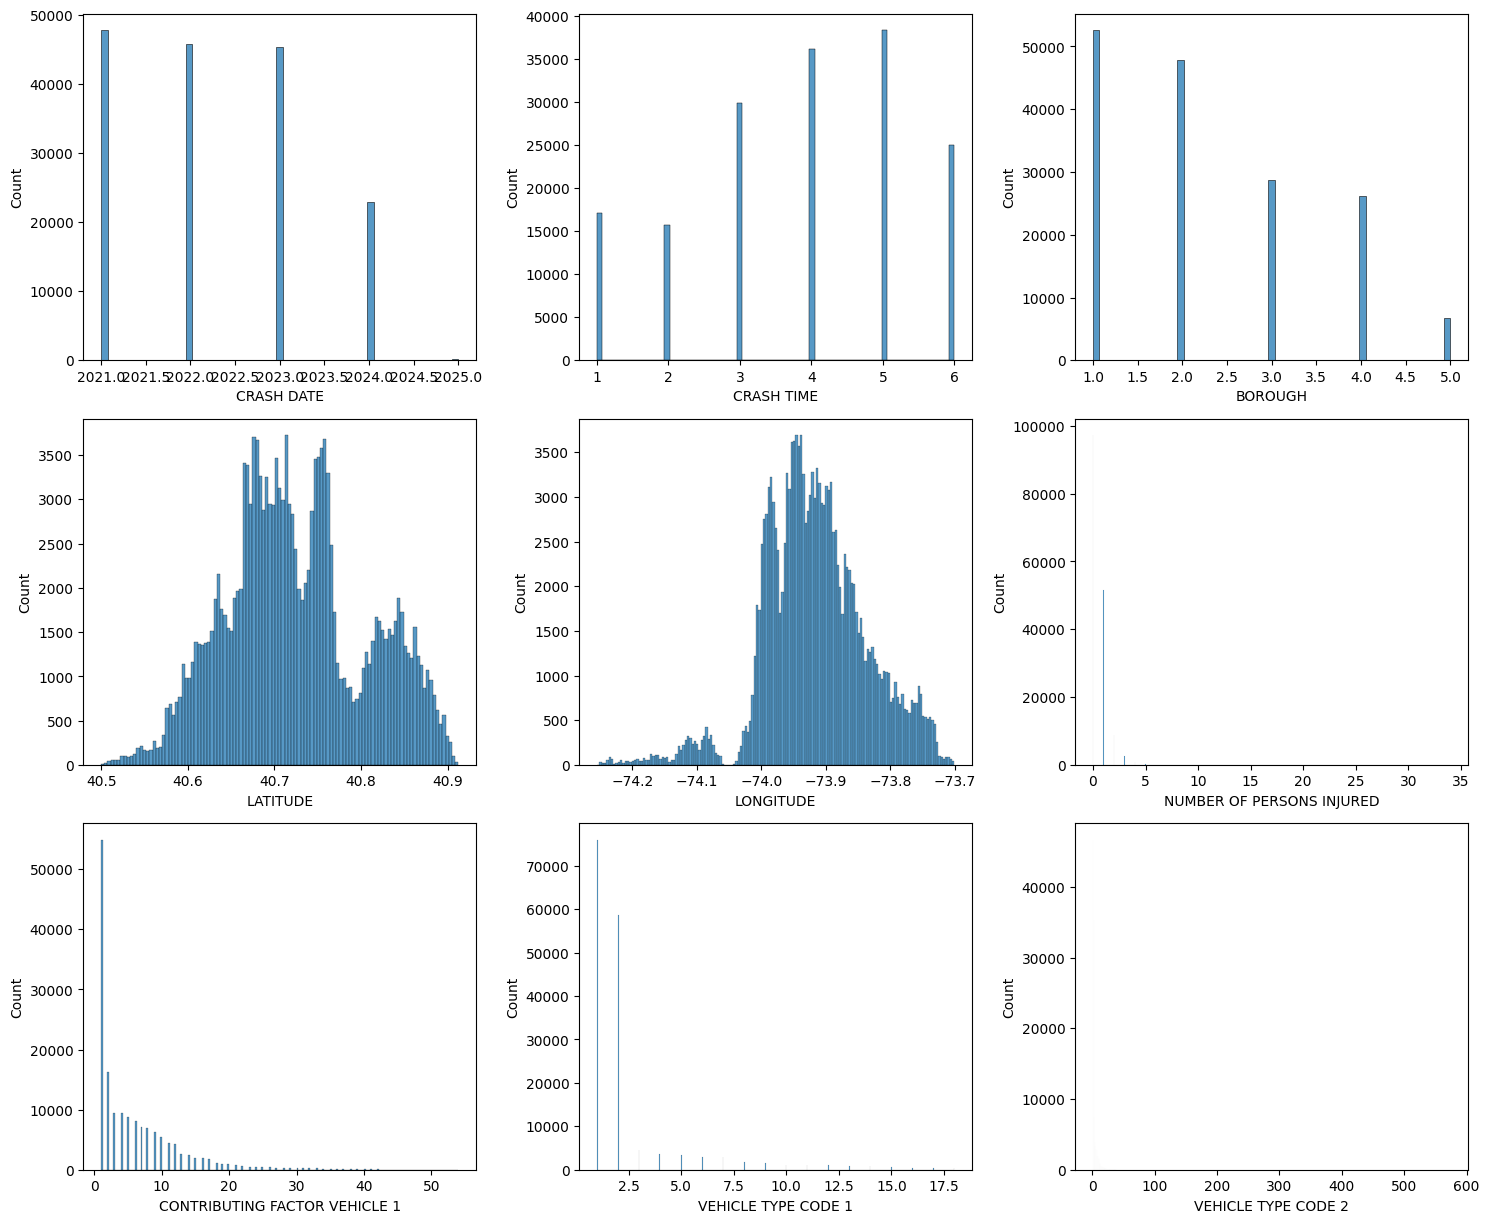

In [ ]:
#-------------------------------------------------
# Count and plot customer base for each features
#-------------------------------------------------
# defining the figure size
plt.figure(figsize=(15, 20))

# list of numerical features to plot
data_features = ['CRASH DATE', 'CRASH TIME', 'BOROUGH',  'LATITUDE',
       'LONGITUDE', 'NUMBER OF PERSONS INJURED',
       'CONTRIBUTING FACTOR VEHICLE 1',
       'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2']
# Histogram for each numerical feature
for i, feature in enumerate(data_features):
    plt.subplot(5, 3, i+1)                # for subplot in the main plot
    sns.histplot(data=data, x=feature)    # histogram plot

plt.tight_layout();   # to add spacing between plots
#-------------------------------------------------

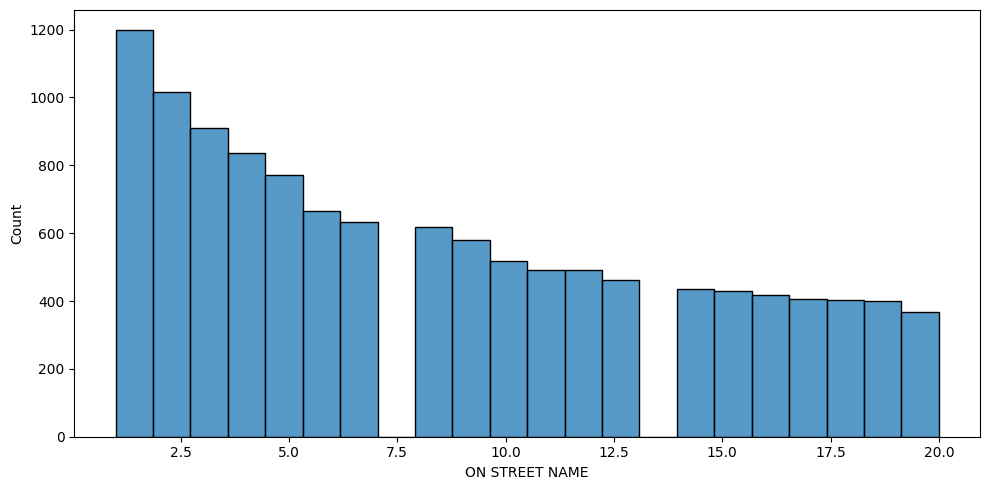

In [ ]:
#-------------------------------------------------
# Count and plot customer base for each features
#-------------------------------------------------
# defining the figure size
plt.figure(figsize=(10, 5))
data_1 = data[data['ON STREET NAME'] != 0.0]
sns.histplot(data=data_1, x='ON STREET NAME')    # histogram plot

plt.tight_layout();   # to add spacing between plots
#-------------------------------------------------

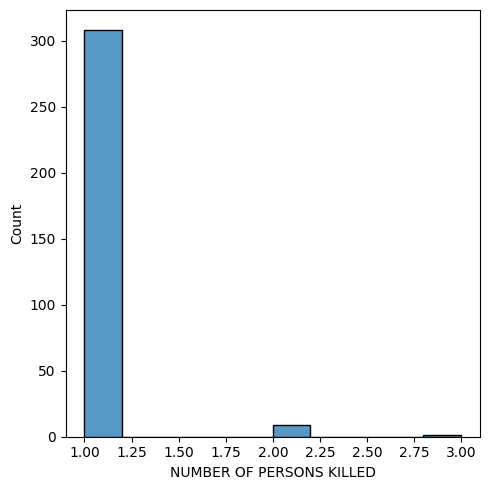

In [ ]:
#-------------------------------------------------
# Count and plot customer base for each features
#-------------------------------------------------
# defining the figure size
plt.figure(figsize=(5, 5))
data_1 = data[data['NUMBER OF PERSONS KILLED'] != 0.0]
sns.histplot(data=data_1, x='NUMBER OF PERSONS KILLED')    # histogram plot

plt.tight_layout();   # to add spacing between plots
#-------------------------------------------------

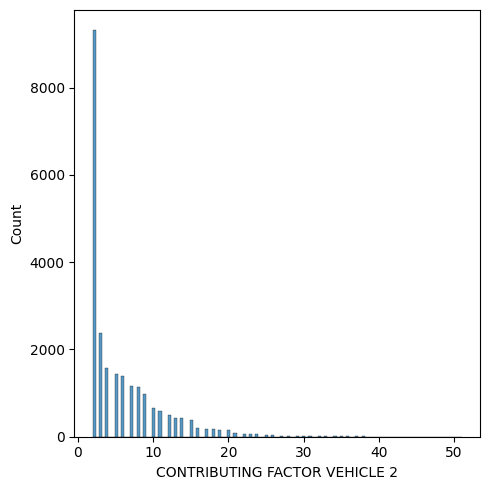

In [ ]:
#-------------------------------------------------
# Count and plot customer base for each features
#-------------------------------------------------
# defining the figure size
plt.figure(figsize=(5, 5))
data_1 = data[data['CONTRIBUTING FACTOR VEHICLE 2'] != 1]
sns.histplot(data=data_1, x='CONTRIBUTING FACTOR VEHICLE 2')    # histogram plot

plt.tight_layout();   # to add spacing between plots
#-------------------------------------------------

### Observations:
- TBD

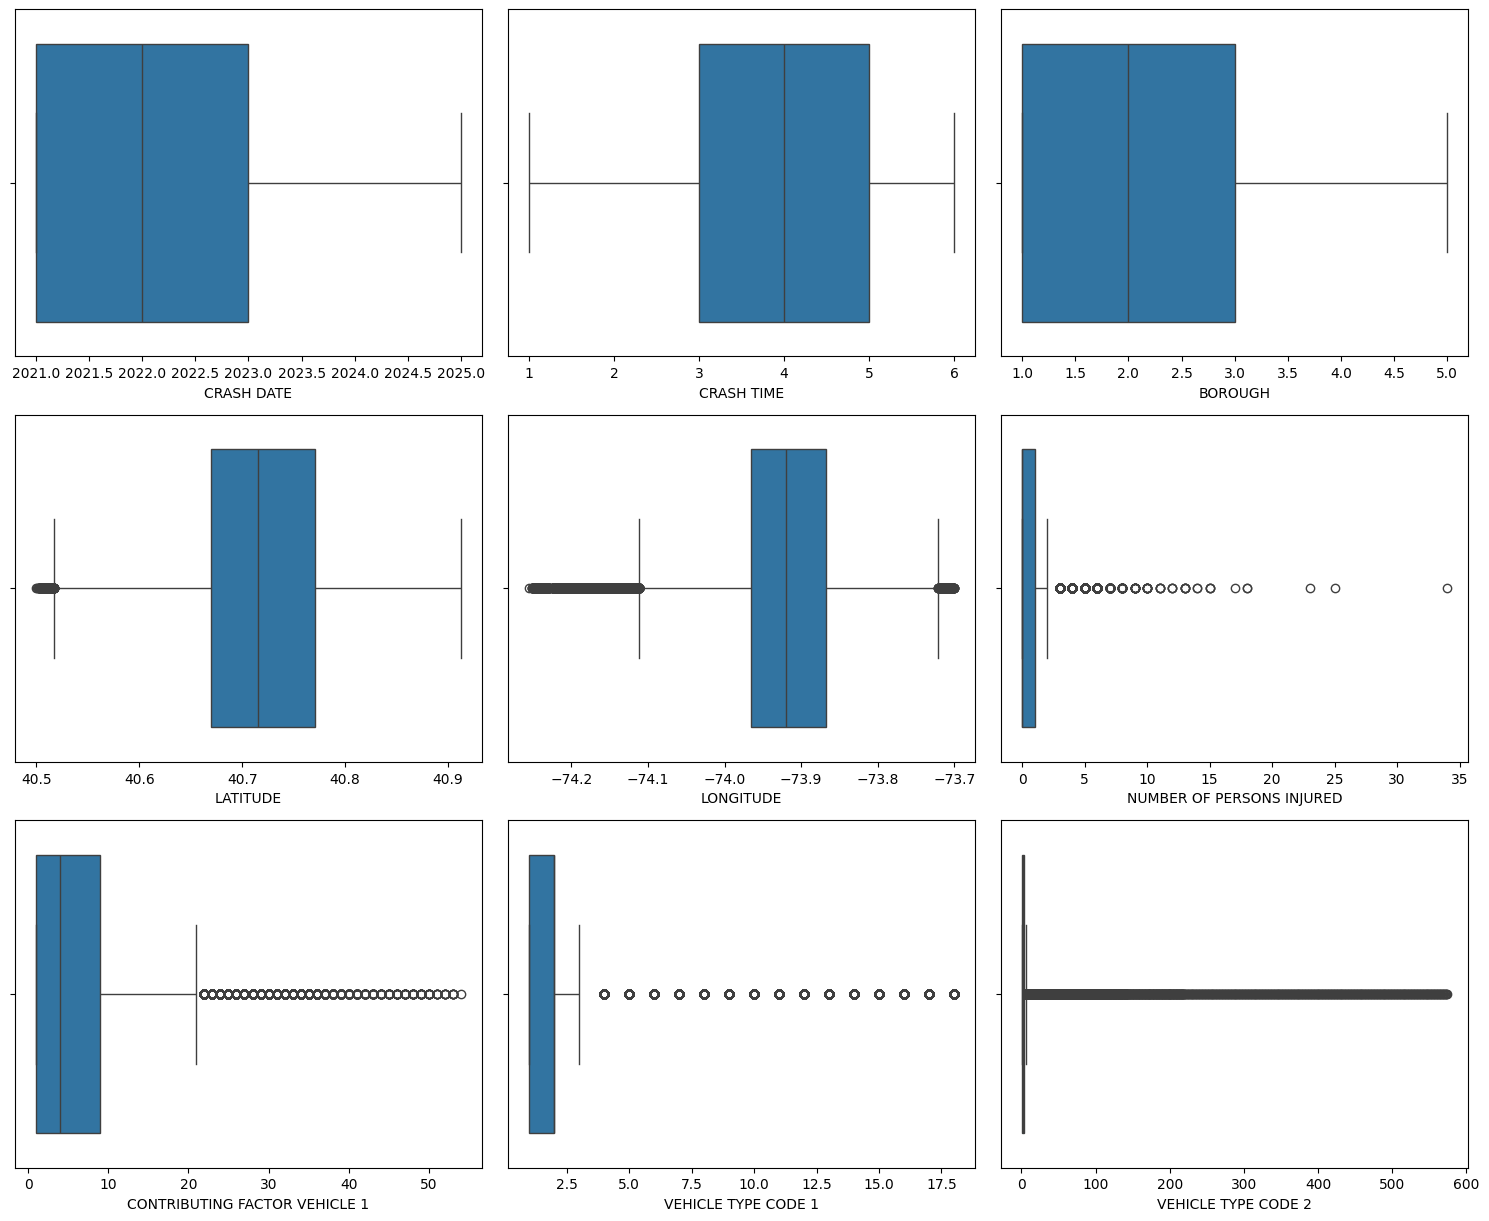

In [ ]:
#-------------------------------------------------
# Plot boxplot for each features
#-------------------------------------------------
# defining the figure size
plt.figure(figsize=(15, 20))
# Boxplot for each numerical feature
for i, feature in enumerate(data_features):
    plt.subplot(5, 3, i+1)               # subplot in the main plot
    sns.boxplot(data=data, x=feature)    # plot the boxplot

plt.tight_layout();    # to add spacing between plots
#-------------------------------------------------

### Observations:
- Year of establishment is highly left skewed, means most of the companies established after 1950.
- Wages are right skewed. But this will be more meaningfull with its units.

### 4.2 Bivariate/Multivariate Analysis

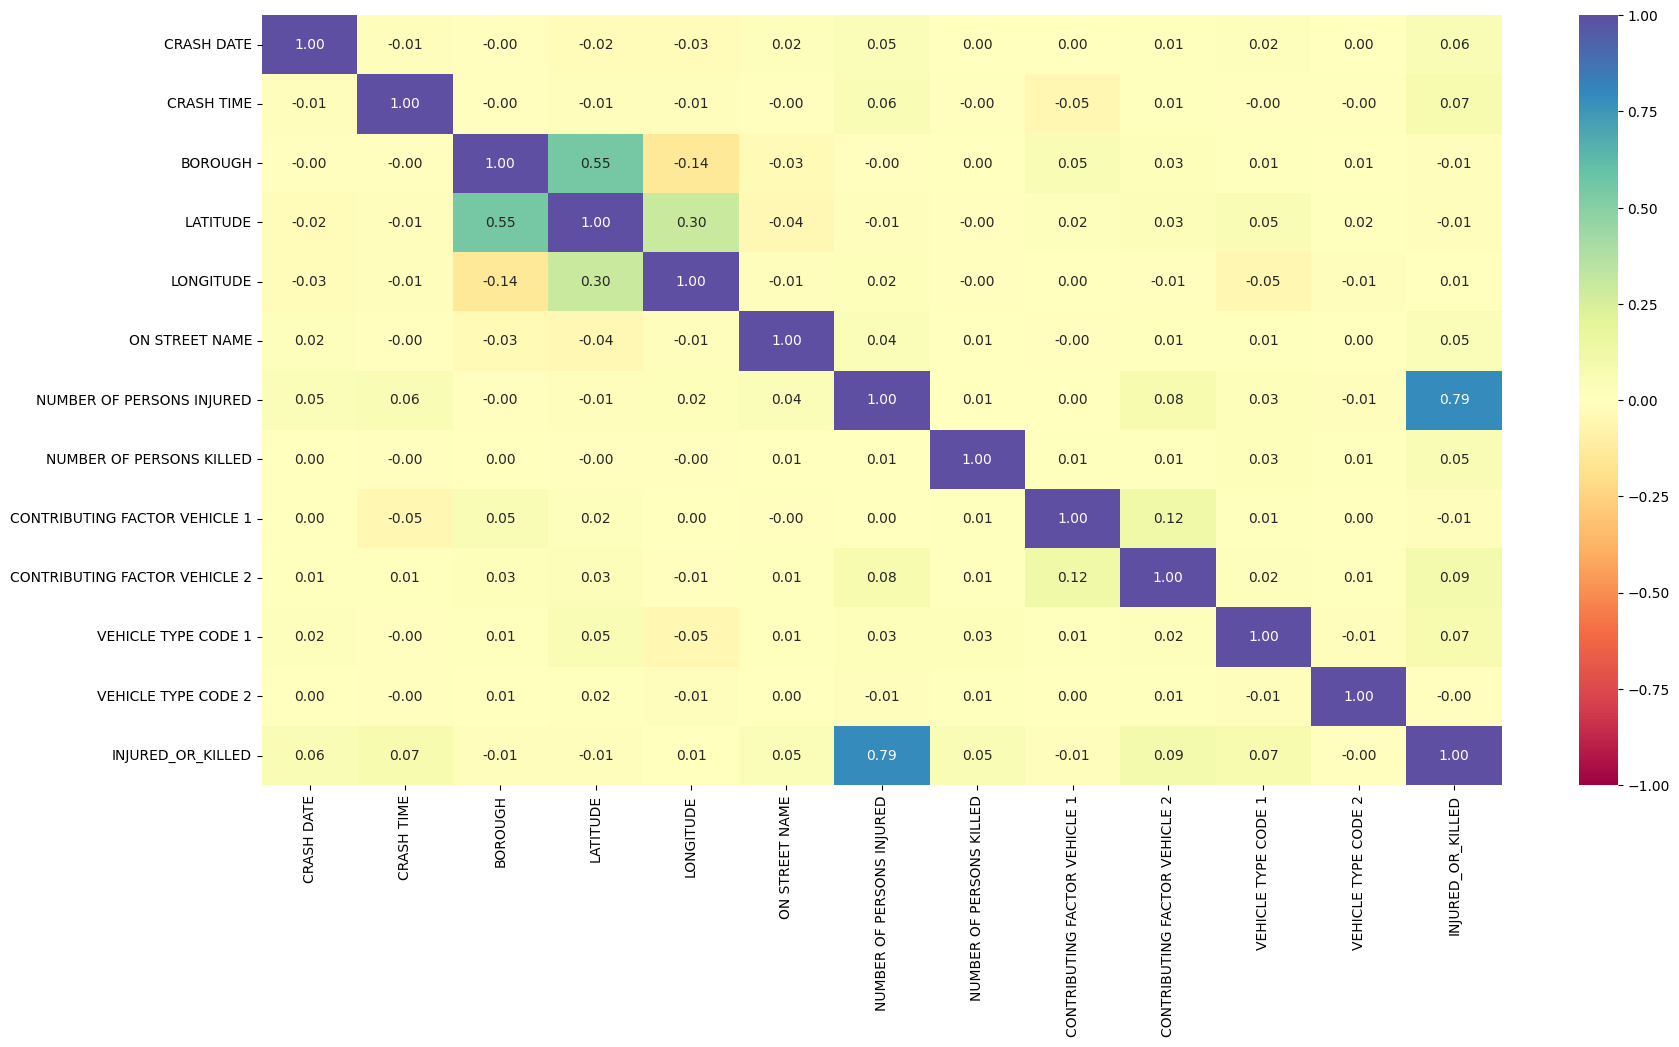

In [ ]:
#-------------------------------------------------
# Create heatmap for correlation
#-------------------------------------------------
# defining the size of the plot
plt.figure(figsize=(20, 10))

# list of numerical features to plot
data_features = ['CRASH DATE', 'CRASH TIME', 'BOROUGH',  'LATITUDE',
       'LONGITUDE', 'ON STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED', 'CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2','INJURED_OR_KILLED']
# plotting the heatmap for correlation
sns.heatmap(data[data_features].corr(),annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral");
#-------------------------------------------------

### Observations:
- Contributing factor 1 and 2 have high corelation.
- Contributing factor 2 and Vehycle type 1 have high corelation.
- Crash date and time have high corelation with injuries or death of person.
- Specific street has high corelation with injuries or death of person.

In [ ]:
#-------------------------------------------------
# Create Scatter plot for all the variables
#-------------------------------------------------
# Scatter plot matrix
plt.figure(figsize=(24, 16))
data_features = ['CRASH DATE', 'CRASH TIME', 'BOROUGH',  'LATITUDE',
       'LONGITUDE', 'ON STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED', 'CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2']
sns.pairplot(data, vars=data_features, hue='INJURED_OR_KILLED', diag_kind='kde');
#-------------------------------------------------

Output hidden; open in https://colab.research.google.com to view.

### Observations:
- It is observed that Latitude wise collision and impacts are distributed. But Longitude wise it is distinct that from -74.0 to -73.8 collision and impacts are concentrated.
- Regarding Vehicle type code, for code 1 initial 6 major type has more injuries or death. But for code 2 inital 1 or 2 types contributes more. These are mainly Sedan and SUVs.
- Initial contributing factor are the mojor cause of most of the crash and injuries/death.

### 4.3 EDA for RQ1: Where do crashes occur most frequently and what is their impact on severity?

<Figure size 2400x1600 with 0 Axes>

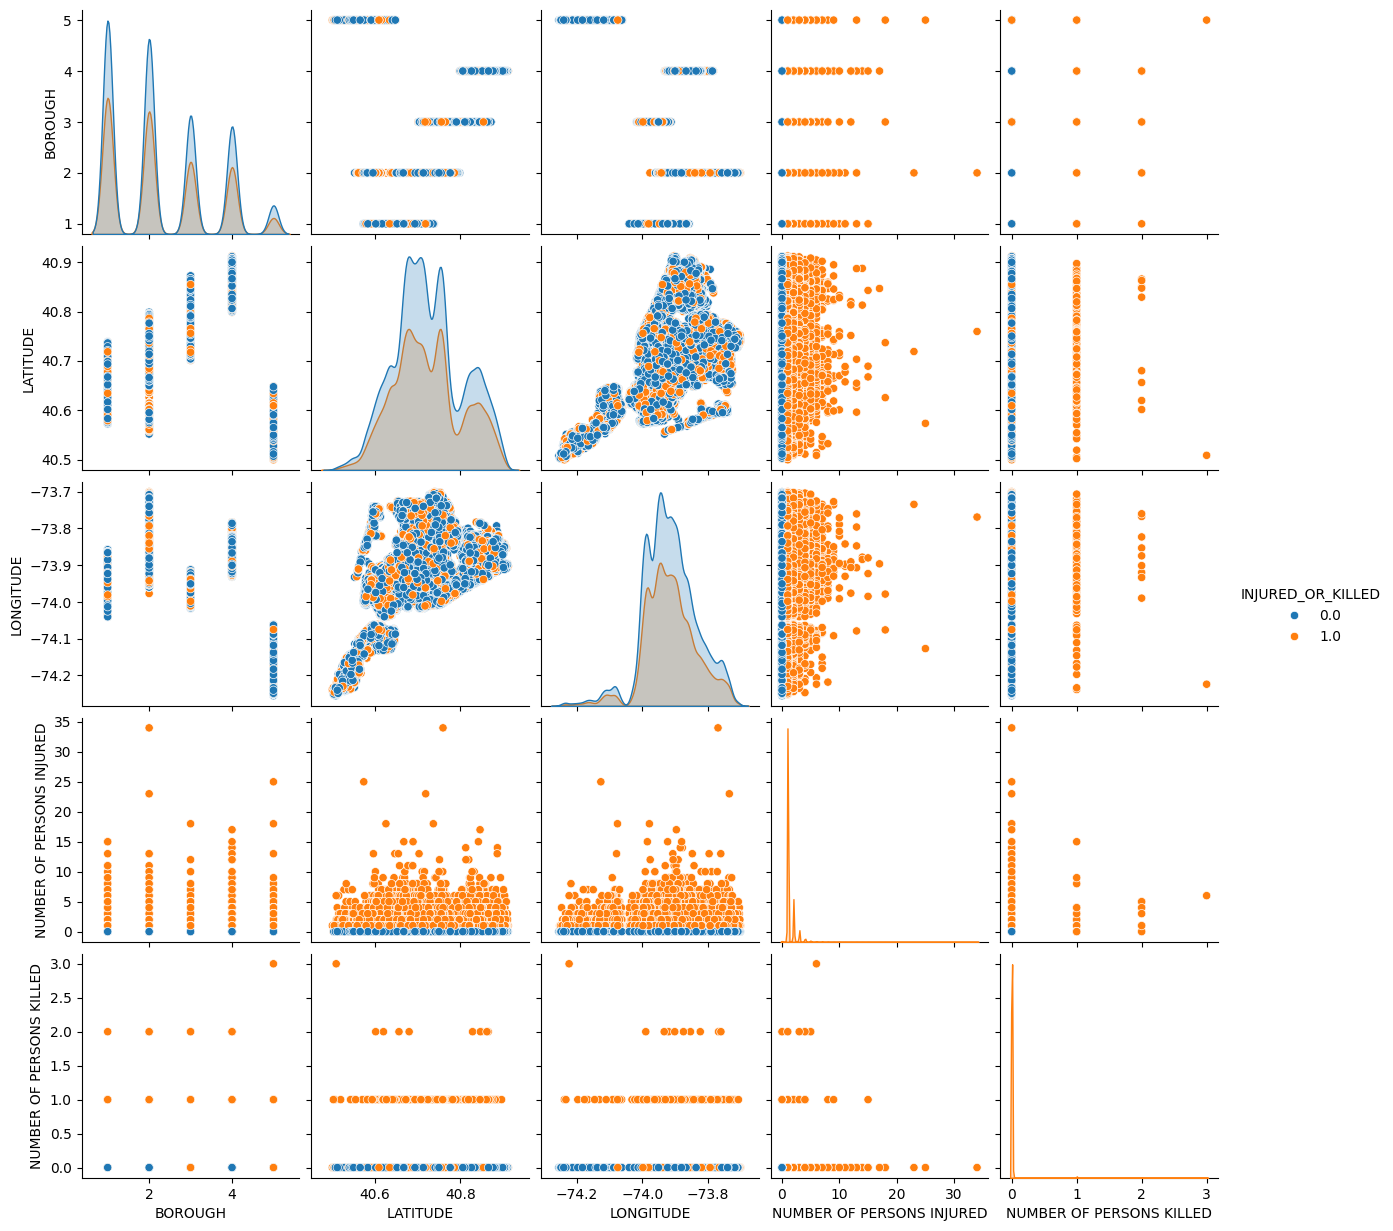

In [ ]:
#-------------------------------------------------
# Create Scatter plot for all the variables
#-------------------------------------------------
# Scatter plot matrix
plt.figure(figsize=(24, 16))
data_features_1 = ['BOROUGH',  'LATITUDE',
       'LONGITUDE', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED']
sns.pairplot(data, vars=data_features_1, hue='INJURED_OR_KILLED', diag_kind='kde');
#-------------------------------------------------

### Observations:
- Location does not have significantly high contribution to injuries or death cases.
-	Latitude 40.6 to 40.6 has more injuries or death cases but not very significantly high. Similarly longitude -74.0 to -73.8 numbers are slightly high.


### 4.4 EDA for RQ2: When are crashes most likely to occur and how does timing affect severity?

<Figure size 2400x1600 with 0 Axes>

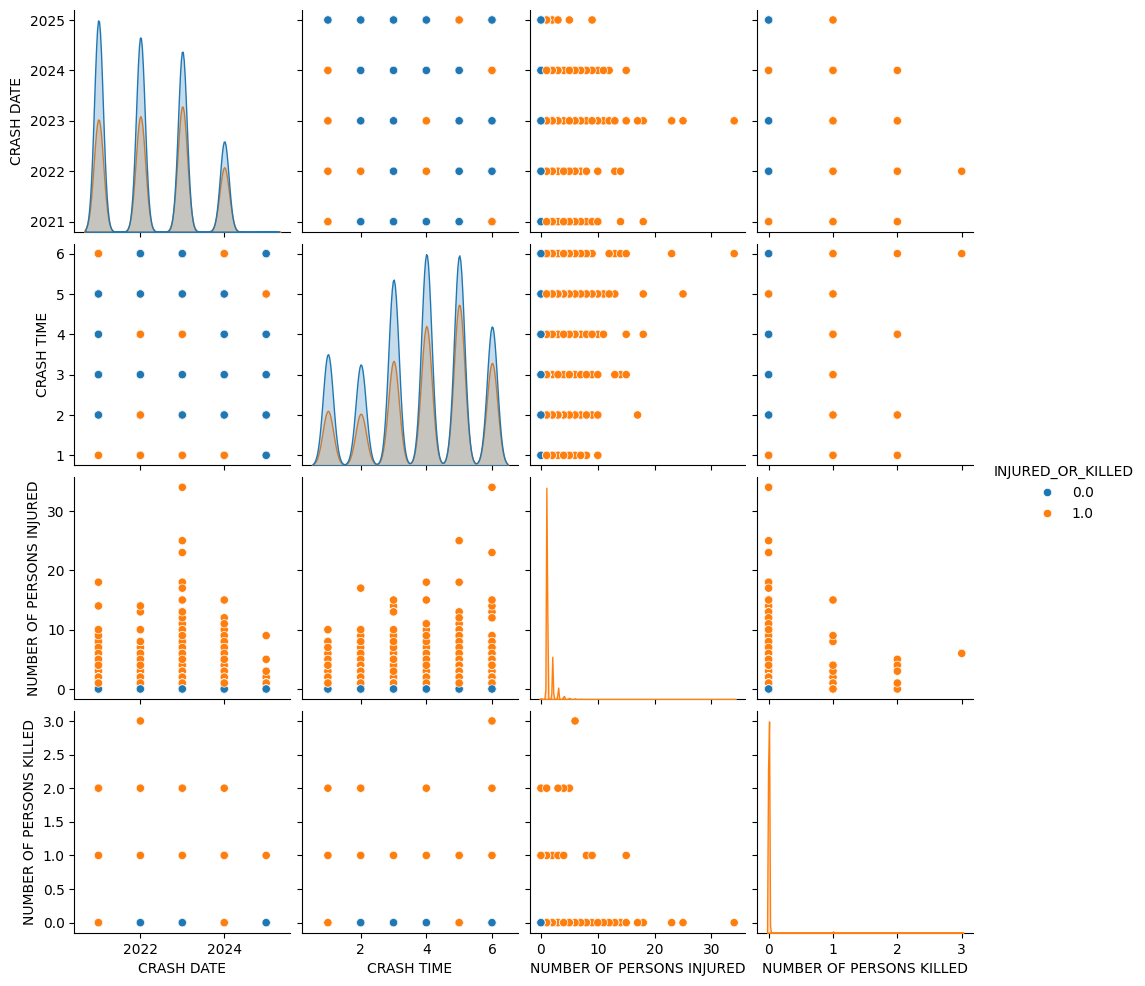

In [ ]:
#-------------------------------------------------
# Create Scatter plot for all the variables
#-------------------------------------------------
# Scatter plot matrix
plt.figure(figsize=(24, 16))
data_features_1 = ['CRASH DATE', 'CRASH TIME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED']
sns.pairplot(data, vars=data_features_1, hue='INJURED_OR_KILLED', diag_kind='kde');
#-------------------------------------------------

### Observations:
- From 12 noon to 8 pm in the evening crashes are more and at the same time injuries or death cases also high.
-	Highest number of people got injured in 2023.


### 4.5 EDA for RQ3: How do specific location features influence crash likelihood and severity?

<Figure size 2400x1600 with 0 Axes>

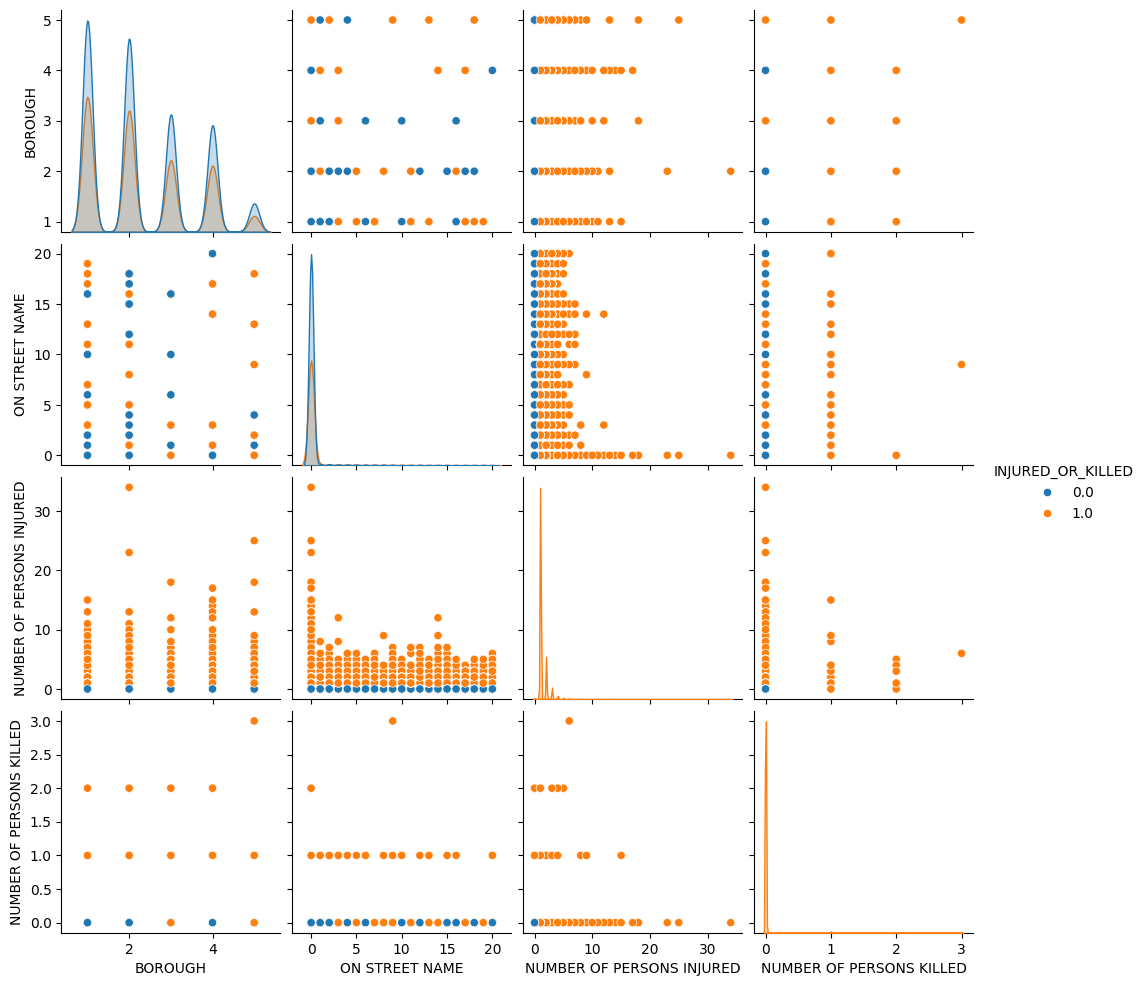

In [ ]:
#-------------------------------------------------
# Create Scatter plot for all the variables
#-------------------------------------------------
# Scatter plot matrix
plt.figure(figsize=(24, 16))
data_features_1 = ['BOROUGH', 'ON STREET NAME', 'NUMBER OF PERSONS INJURED',
       'NUMBER OF PERSONS KILLED']
sns.pairplot(data, vars=data_features_1, hue='INJURED_OR_KILLED', diag_kind='kde');
#-------------------------------------------------

### Observations:
- Some streets has high injuries or death cases.
-	BROADWAY and ATLANTIC AVENUE are the street names where crashes happens most.

### 4.6 EDA for RQ4: What are the most common contributing causes of crashes and how do they vary by vehicle type?

<Figure size 2400x1600 with 0 Axes>

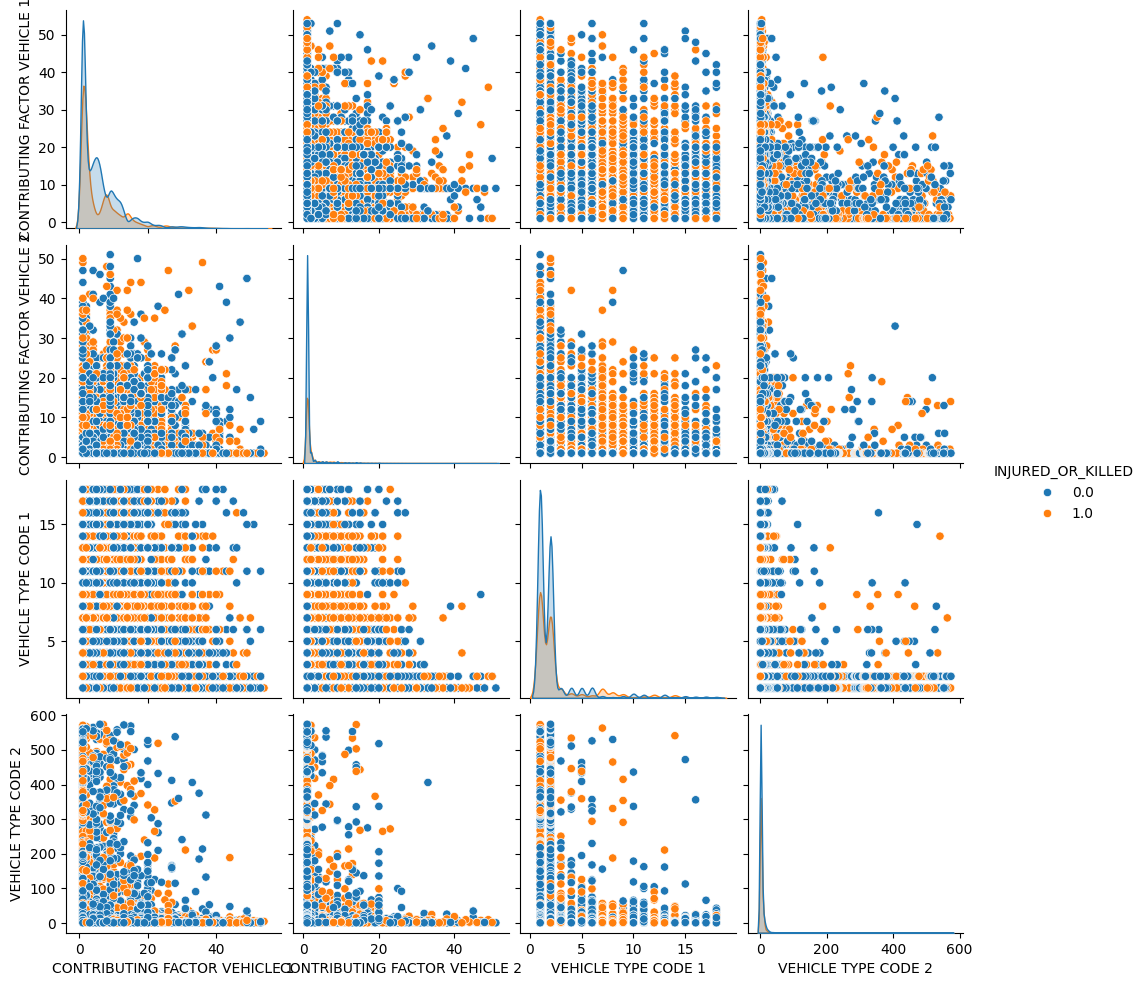

In [ ]:
#-------------------------------------------------
# Create Scatter plot for all the variables
#-------------------------------------------------
# Scatter plot matrix
plt.figure(figsize=(24, 16))
data_features_1 = ['CONTRIBUTING FACTOR VEHICLE 1',
       'CONTRIBUTING FACTOR VEHICLE 2', 'VEHICLE TYPE CODE 1',
       'VEHICLE TYPE CODE 2']
sns.pairplot(data, vars=data_features_1, hue='INJURED_OR_KILLED', diag_kind='kde');
#-------------------------------------------------

### Observations:
- For vehicle type 1 most of the contributing factor 1 impacts.
-	But for vehicle type 2, contributing factors are not that distributed. Some specific vehicle types contributed most of the crashes.
-	Sedan and “Station Wagon/Sport Utility Vehicle” are the highest contributor of crashes. Injuries or death cases also highest for these two vehicle types.

# 5. Data pre-processing - for model building

In [ ]:
#----------------------------------------------------------------------------
# defining the explanatory (independent) and response (dependent) variables
#----------------------------------------------------------------------------
# Response (dependent) variable is TOTAL_INJURED_AND_KILLED
# Rest of the variable will be explanatory (independent) variable
#----------------------------------------------------------------------------

X = data.drop(["INJURED_OR_KILLED"], axis=1)
y = data["INJURED_OR_KILLED"]
print('Size of X : ',X.shape)
print('Size of y : ',y.shape)

Size of X :  (161977, 12)
Size of y :  (161977,)


In [ ]:
# Splitting data into training, validation and test set:

# first we split data into 2 parts, say temporary and test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# then we split the temporary set into train and validation
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42)

print('Training dataset -> X_train : ', X_train.shape)
print('Validation dataset -> X_val : ', X_val.shape)
print('Test dataset -> X_test : ', X_test.shape)

Training dataset -> X_train :  (103664, 12)
Validation dataset -> X_val :  (25917, 12)
Training dataset -> X_test :  (32396, 12)


### Observations:
- The main dataset is splitted successfully for Training, test and validation.

# 6. Model Building - Original Data

In [ ]:
#------------------------------------------------------------------------------
# Compute different metrics to check performance of a classification model built using sklearn
#------------------------------------------------------------------------------
def model_performance_classification(model, predictors, target):
    # model: classifier
    # predictors: independent variables
    # target: dependent variable

    # predicting using the independent variables
    prediction = model.predict(predictors)

    accuracy = accuracy_score(target, prediction)  # to compute Accuracy
    recall = recall_score(target, prediction)  # to compute Recall
    precision = precision_score(target, prediction)  # to compute Precision
    f1 = f1_score(target, prediction)  # to compute F1-score

    # creating a dataframe of metrics
    df_performance = pd.DataFrame(
        {"Accuracy": accuracy, "Recall": recall, "Precision": precision, "F1 Score": f1,},
        index=[0],
    )

    return df_performance

In [ ]:
#------------------------------------------------------------------------------
# Plot the Confusion Matrix
#------------------------------------------------------------------------------
def plot_confusion_matrix(model, predictors, target):
    # model: classifier
    # predictors: independent variables
    # target: dependent variable

    # Predict the target values using the provided model and predictors
    y_prediction = model.predict(predictors)

    # Compute the confusion matrix comparing the true target values with the predicted values
    y_confusion_matrix = confusion_matrix(target, y_prediction)

    # Create labels for each cell in the confusion matrix with both count and percentage
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / y_confusion_matrix.flatten().sum())]
            for item in y_confusion_matrix.flatten()
        ]
    ).reshape(2, 2)    # reshaping to a matrix

    # Set the figure size for the plot
    plt.figure(figsize=(6, 4))

    # Plot the confusion matrix as a heatmap with the labels
    sns.heatmap(y_confusion_matrix, annot=labels, fmt="")

    # Add a label to the y-axis
    plt.ylabel("True Label")

    # Add a label to the x-axis
    plt.xlabel("Predicted Label")

### 6.1 Decision Tree (sklearn default)

In [ ]:
#------------------------------------------------------------------------------
# creating an instance of the decision tree model
#------------------------------------------------------------------------------
decision_tree_1 = DecisionTreeClassifier(random_state=42)    # random_state sets a seed value and enables reproducibility

# fitting the model to the training data
decision_tree_1.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

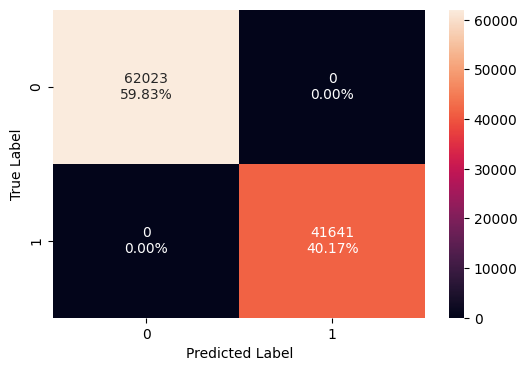

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(decision_tree_1, X_train, y_train)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
decision_tree_1_train_perf = model_performance_classification(decision_tree_1, X_train, y_train)
decision_tree_1_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


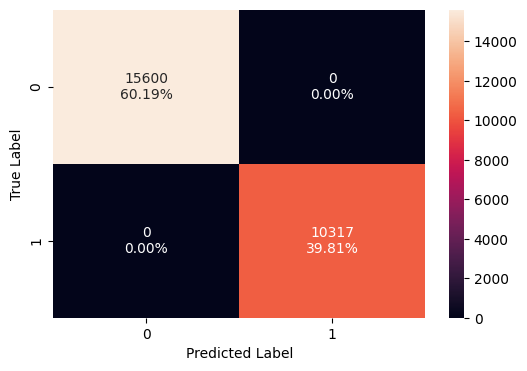

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(decision_tree_1, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
decision_tree_1_val_perf = model_performance_classification(decision_tree_1, X_val , y_val)
decision_tree_1_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### 6.2 Random Forest Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train the random forest classifier
#------------------------------------------------------------------------------
rf_estimator_1=RandomForestClassifier(random_state=42)
rf_estimator_1.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

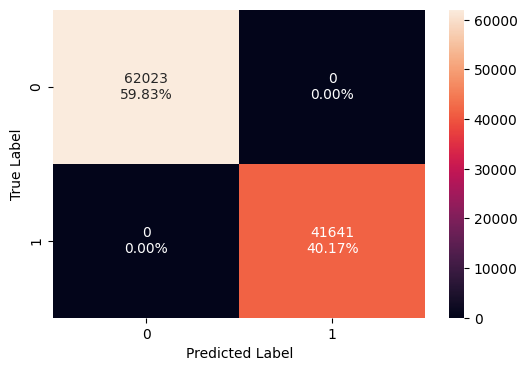

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_1, X_train, y_train)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
rf_estimator_1_train_perf = model_performance_classification(rf_estimator_1, X_train, y_train)
rf_estimator_1_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


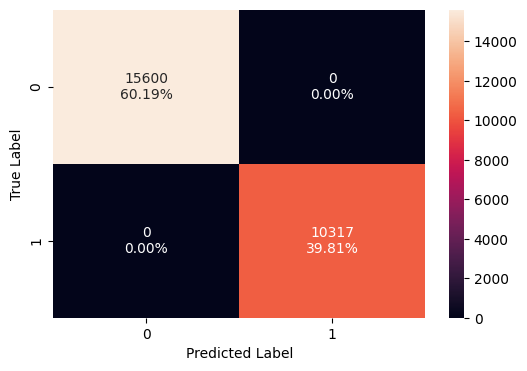

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_1, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
rf_estimator_1_val_perf = model_performance_classification(rf_estimator_1, X_val , y_val)
rf_estimator_1_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### 6.3 XGBoost Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train XGBoost Classifier
#------------------------------------------------------------------------------
xgb_estimator_1 = XGBClassifier(random_state=42,eval_metric='logloss')
xgb_estimator_1.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

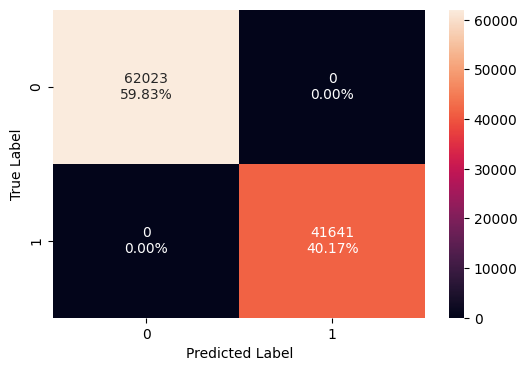

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_1, X_train, y_train)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
xgb_estimator_1_train_perf = model_performance_classification(xgb_estimator_1, X_train, y_train)
xgb_estimator_1_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


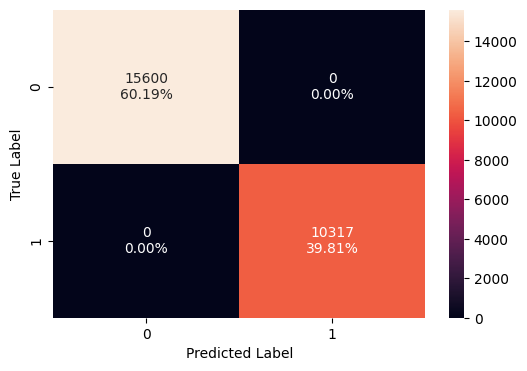

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_1, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
xgb_estimator_1_val_perf = model_performance_classification(xgb_estimator_1, X_val , y_val)
xgb_estimator_1_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### Observations:
The Accuracy score, Recall score, Precision score and F1 Score for training and validation data are same. It is mainly because the notable cases in the target variable is very less.

So, oversampling , undersampling and tuning will be done for much reliable outcome.

# 7. Model Building - Oversampled Data

### Oversampling train data using SMOTE

In [ ]:
#------------------------------------------------------------------------------
# Fit SMOTE on train data(Synthetic Minority Oversampling Technique)
#------------------------------------------------------------------------------
import os
os.environ["PYTHONWARNINGS"] = "ignore"
X_train = X_train.fillna(0)

sm = SMOTE(random_state=42)

X_train_over, y_train_over = sm.fit_resample(X_train, y_train)
#------------------------------------------------------------------------------

In [ ]:
print("Before OverSampling, count of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, count of label '0': {} \n".format(sum(y_train == 0)))

print("After OverSampling, count of label '1': {}".format(sum(y_train_over == 1)))
print("After OverSampling, count of label '0': {} \n".format(sum(y_train_over == 0)))

print("After OverSampling, the shape of train_X: {}".format(X_train_over.shape))
print("After OverSampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before OverSampling, count of label '1': 41641
Before OverSampling, count of label '0': 62023 

After OverSampling, count of label '1': 62023
After OverSampling, count of label '0': 62023 

After OverSampling, the shape of train_X: (124046, 12)
After OverSampling, the shape of train_y: (124046,) 



### 7.1 Random Forest Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train the random forest classifier
#------------------------------------------------------------------------------
rf_estimator_2=RandomForestClassifier(random_state=42)
rf_estimator_2.fit(X_train_over,y_train_over)

RandomForestClassifier(random_state=42)

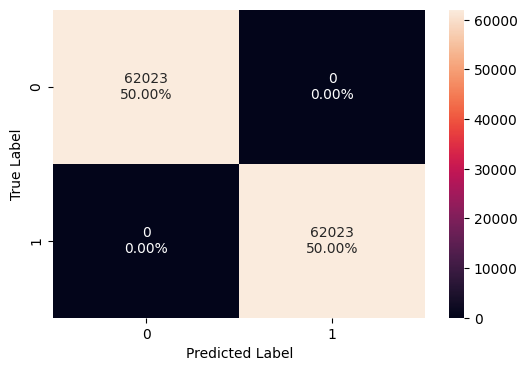

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_2, X_train_over, y_train_over)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
rf_estimator_2_train_perf = model_performance_classification(rf_estimator_2, X_train_over, y_train_over)
rf_estimator_2_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


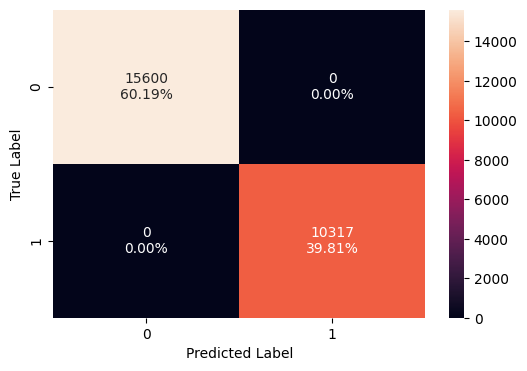

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_2, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
rf_estimator_2_val_perf = model_performance_classification(rf_estimator_2, X_val , y_val)
rf_estimator_2_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### 7.2 XGBoost Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train XGBoost Classifier
#------------------------------------------------------------------------------
xgb_estimator_2 = XGBClassifier(random_state=42,eval_metric='logloss')
xgb_estimator_2.fit(X_train_over, y_train_over)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

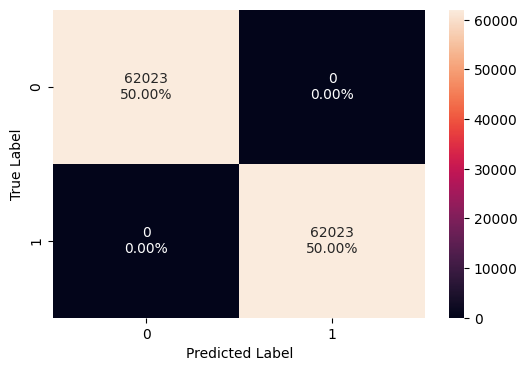

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_2, X_train_over, y_train_over)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
xgb_estimator_2_train_perf = model_performance_classification(xgb_estimator_2, X_train_over, y_train_over)
xgb_estimator_2_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


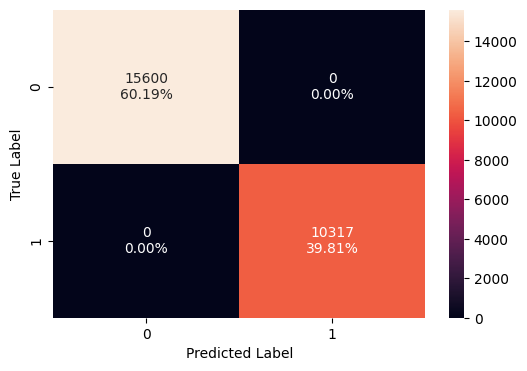

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_2, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
xgb_estimator_2_val_perf = model_performance_classification(xgb_estimator_2, X_val , y_val)
xgb_estimator_2_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### Observations:
For oversampling as well, the Accuracy score, Recall score, Precision score and F1 Score for training and validation data are same. It is mainly because the notable cases in the target variable is very less.

So, we will explore undersampling and hyper parameter tuning for much reliable outcome.

# 8. Model Building - Undersampled Data

### Undesampling train data

In [ ]:
#------------------------------------------------------------------------------
# Create under sample dataset
#------------------------------------------------------------------------------
random_under_sampling = RandomUnderSampler(random_state=42, sampling_strategy = 1)
X_train_un, y_train_un = random_under_sampling.fit_resample(X_train, y_train)
X_train_use = X_train_un
y_train_use = y_train_un

In [ ]:
print("Before Under Sampling, count of label '1': {}".format(sum(y_train == 1)))
print("Before Under Sampling, count of label '0': {} \n".format(sum(y_train == 0)))

print("After Under Sampling, count of label '1': {}".format(sum(y_train_use == 1)))
print("After Under Sampling, count of label '0': {} \n".format(sum(y_train_use == 0)))

print("After Under Sampling, the shape of train_X: {}".format(X_train_use.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_use.shape))

Before Under Sampling, count of label '1': 41641
Before Under Sampling, count of label '0': 62023 

After Under Sampling, count of label '1': 41641
After Under Sampling, count of label '0': 41641 

After Under Sampling, the shape of train_X: (83282, 12)
After Under Sampling, the shape of train_y: (83282,) 



### 8.1 Random Forest Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train the random forest classifier
#------------------------------------------------------------------------------
rf_estimator_3=RandomForestClassifier(random_state=42)
rf_estimator_3.fit(X_train_use,y_train_use)

RandomForestClassifier(random_state=42)

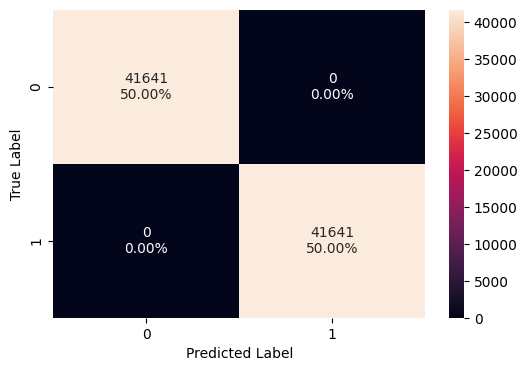

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_3, X_train_use, y_train_use)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
rf_estimator_3_train_perf = model_performance_classification(rf_estimator_3, X_train_use, y_train_use)
rf_estimator_3_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


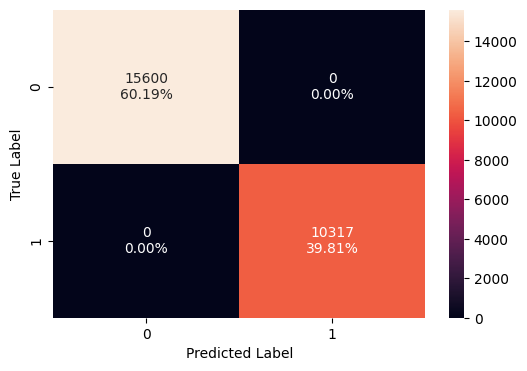

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_3, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
rf_estimator_3_val_perf = model_performance_classification(rf_estimator_3, X_val , y_val)
rf_estimator_3_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### 8.2 XGBoost Classifier

In [ ]:
#------------------------------------------------------------------------------
# Train XGBoost Classifier
#------------------------------------------------------------------------------
xgb_estimator_3 = XGBClassifier(random_state=42,eval_metric='logloss')
xgb_estimator_3.fit(X_train_use, y_train_use)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

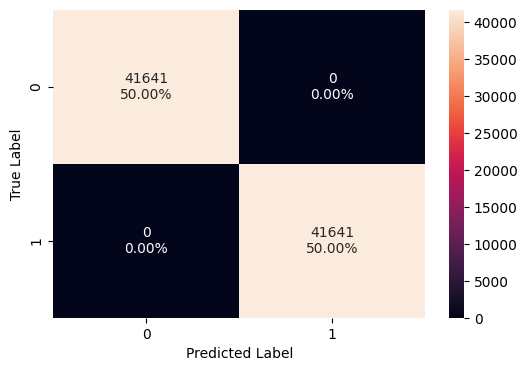

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_3, X_train_use, y_train_use)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
xgb_estimator_3_train_perf = model_performance_classification(xgb_estimator_3, X_train_use, y_train_use)
xgb_estimator_3_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


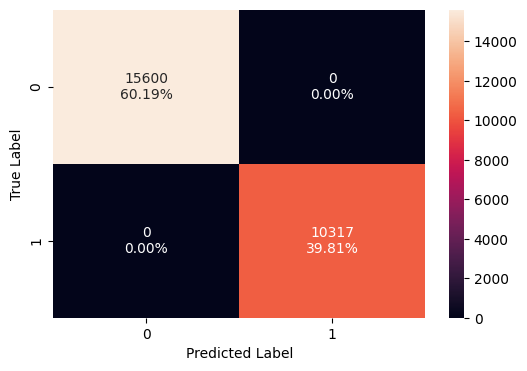

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_estimator_3, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
xgb_estimator_3_val_perf = model_performance_classification(xgb_estimator_3, X_val , y_val)
xgb_estimator_3_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### Observations:
For undersampling as well, the Accuracy score, Recall score, Precision score and F1 Score for training and validation data are same. It is mainly because the notable cases in the target variable is very less.

So, we will explore hyper parameter tuning for much reliable outcome.

# 9. Hyperparameter tuning

For each classification models GridSearchCV and RandomizedSearchCV used along with the specific parameter configuration for tuning.
For cross validation KFold is used.

In [ ]:
#------------------------------------------------------------------------------
# defining kfold
#------------------------------------------------------------------------------
kfold = KFold(n_splits=5, random_state=42, shuffle = True)

## 9.1 Random Forest Classifier

### 9.1.1 Random Forest Classifier - Tune GridSearchCV

In [ ]:
#------------------------------------------------------------------------------
# Check the default values in the parameter set
#------------------------------------------------------------------------------
RandomForestClassifier().get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [ ]:
%%time
#------------------------------------------------------------------------------
# Choose the type of classifier.
rf1 = RandomForestClassifier(random_state=42)

# Grid of parameters to choose from
parameters = {"n_estimators": [50,100],#[150,200,250],
    "min_samples_leaf": np.arange(5, 10),
    "max_features": np.arange(0.3, 0.5), #(0.2, 0.7, 0.1),
    "max_samples": np.arange(0.3, 0.7),#(0.3, 0.7, 0.1),
    "class_weight" : ['balanced'],#['balanced', 'balanced_subsample'],
    "max_depth":np.arange(5,10),#(3,4,5),
    "min_impurity_decrease":[0.001, 0.002] #[0.001, 0.002, 0.003]
             }

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(rf1, parameters, scoring=acc_scorer, cv=kfold, n_jobs= -1, verbose = 2)
# verbose = 2 tells about the number of fits, which can give an idea of how long will the model take in tuning
# n_jobs = -1 so that all CPU cores can be run parallelly to optimize the Search

grid_obj = grid_obj.fit(X_train, y_train)

# Print the best combination of parameters
grid_obj.best_params_
#------------------------------------------------------------------------------

Fitting 5 folds for each of 100 candidates, totalling 500 fits
CPU times: user 10.3 s, sys: 1.97 s, total: 12.3 s
Wall time: 10min 7s


{'class_weight': 'balanced',
 'max_depth': np.int64(6),
 'max_features': np.float64(0.3),
 'max_samples': np.float64(0.3),
 'min_impurity_decrease': 0.001,
 'min_samples_leaf': np.int64(5),
 'n_estimators': 50}

In [ ]:
grid_obj.best_score_

np.float64(0.9982676346330503)

In [ ]:
# Set the clf to the best combination of parameters
rf_estimator_tuned_GSCV = RandomForestClassifier(
    class_weight= "balanced",
    max_depth= 6,
    max_features= 0.3,
    max_samples= 0.3,
    min_impurity_decrease= 0.001,
    min_samples_leaf= 5,
    n_estimators= 50,
    random_state=42,
)

# Fit the best algorithm to the data.
rf_estimator_tuned_GSCV.fit(X_train, y_train)
X_train_use = X_train
y_train_use = y_train

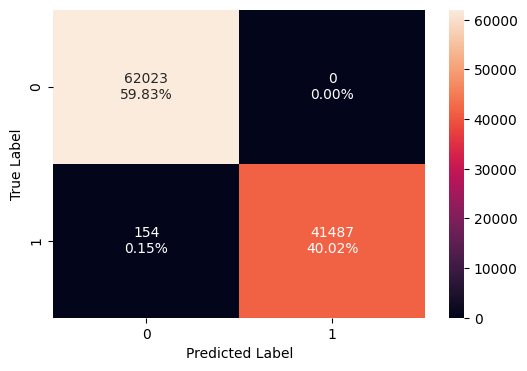

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_tuned_GSCV, X_train_use, y_train_use)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
rf_estimator_tune_GSCV_train_perf = model_performance_classification(rf_estimator_tuned_GSCV, X_train_use, y_train_use)
rf_estimator_tune_GSCV_train_perf

,Accuracy,Recall,Precision,F1 Score
0,0.998514,0.996302,1.0,0.998147


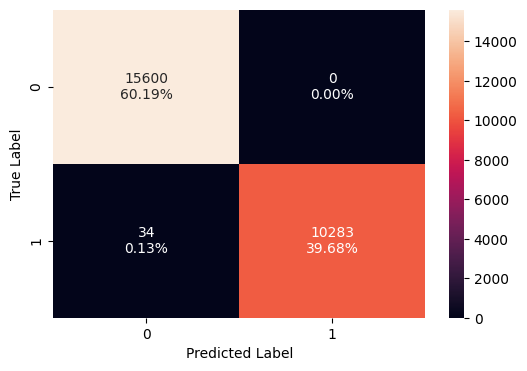

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_tuned_GSCV, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
rf_estimator_tune_GSCV_val_perf = model_performance_classification(rf_estimator_tuned_GSCV, X_val , y_val)
rf_estimator_tune_GSCV_val_perf

,Accuracy,Recall,Precision,F1 Score
0,0.998688,0.996704,1.0,0.99835


### Observations:
After hyper parameter tuning it is observed that Accuracy, Recall and F1 scores are 99.8%.

### 9.1.2 Random Forest Classifier - Tune RandomSearchCV

In [ ]:
%%time
#------------------------------------------------------------------------------
# Choose the type of classifier.
rf2 = RandomForestClassifier(random_state=42)

# Grid of parameters to choose from
parameters = {"n_estimators": [50,100],#[150,200,250],
    "min_samples_leaf": np.arange(5, 10),
    "max_features": np.arange(0.3, 0.5), #(0.2, 0.7, 0.1),
    "max_samples": np.arange(0.3, 0.7),#(0.3, 0.7, 0.1),
    "class_weight" : ['balanced'],#['balanced', 'balanced_subsample'],
    "max_depth":np.arange(5,10),#(3,4,5),
    "min_impurity_decrease":[0.001, 0.002] #[0.001, 0.002, 0.003]
             }

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the random search
grid_obj = RandomizedSearchCV(rf2, parameters,n_iter=30, scoring=acc_scorer,cv=kfold, random_state = 42, n_jobs = -1, verbose = 2)
# using n_iter = 30, so randomized search will try 30 different combinations of hyperparameters
# by default, n_iter = 10

grid_obj = grid_obj.fit(X_train, y_train)

# Print the best combination of parameters
grid_obj.best_params_
#------------------------------------------------------------------------------

Fitting 5 folds for each of 30 candidates, totalling 150 fits
CPU times: user 3.79 s, sys: 598 ms, total: 4.39 s
Wall time: 2min 48s


{'n_estimators': 50,
 'min_samples_leaf': np.int64(6),
 'min_impurity_decrease': 0.001,
 'max_samples': np.float64(0.3),
 'max_features': np.float64(0.3),
 'max_depth': np.int64(6),
 'class_weight': 'balanced'}

In [ ]:
grid_obj.best_score_

np.float64(0.9982676346330503)

In [ ]:
# Set the clf to the best combination of parameters
rf_estimator_tuned_RSCV = RandomForestClassifier(
    class_weight="balanced",
    max_features=0.3,
    max_samples=0.3,
    min_samples_leaf=6,
    n_estimators=50,
    random_state=42,
    max_depth=6,
    min_impurity_decrease=0.001,
)

# Fit the best algorithm to the data.
rf_estimator_tuned_RSCV.fit(X_train, y_train)
X_train_use = X_train
y_train_use = y_train

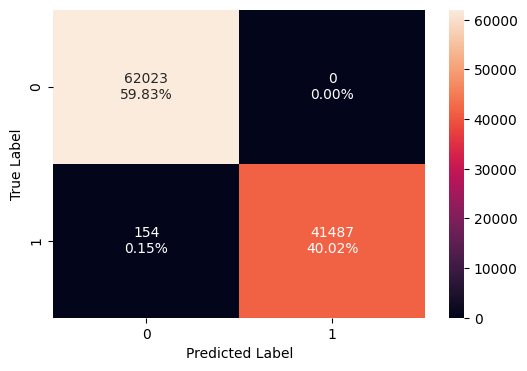

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_tuned_RSCV, X_train_use, y_train_use)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
rf_estimator_tune_RSCV_train_perf = model_performance_classification(rf_estimator_tuned_RSCV, X_train_use, y_train_use)
rf_estimator_tune_RSCV_train_perf

,Accuracy,Recall,Precision,F1 Score
0,0.998514,0.996302,1.0,0.998147


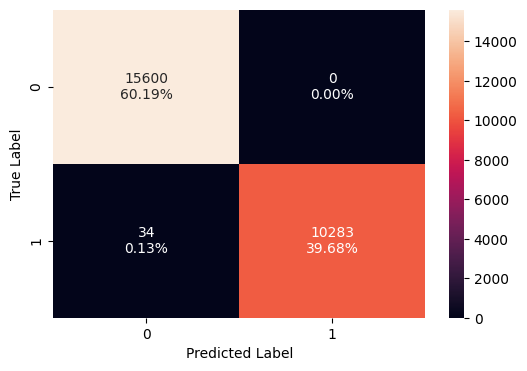

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_tuned_RSCV, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
rf_estimator_tune_RSCV_val_perf = model_performance_classification(rf_estimator_tuned_RSCV, X_val , y_val)
rf_estimator_tune_RSCV_val_perf

,Accuracy,Recall,Precision,F1 Score
0,0.998688,0.996704,1.0,0.99835


### Observations:
After hyper parameter tuning it is observed that Accuracy, Recall and F1 scores are 99.8%. But for classifier Randomforest values for grid search CV and Random search CV are similar.

## 9.2 XGBoost Classifier

### 9.2.1 XGBoost Classifier - Tune RandomSearchCV

In [ ]:
%%time
#------------------------------------------------------------------------------
# Choose the type of classifier.
xgb_tuned = XGBClassifier(random_state=42,eval_metric='logloss')

# Grid of parameters to choose from
## add from
parameters = {
    "n_estimators": np.arange(50,100),
    "scale_pos_weight":[1,2],
    "subsample":[0.8,1.0],
    "learning_rate":[0.1,0.05],
    "gamma":[0,1],
    "colsample_bytree":[0.8,1.0],
    "colsample_bylevel":[0.8,1.0]
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = RandomizedSearchCV(xgb_tuned, parameters,n_iter=30, scoring=acc_scorer,cv=kfold, random_state = 42, n_jobs = -1, verbose = 2)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned_RSCV = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned_RSCV.fit(X_train, y_train)

grid_obj.best_params_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
CPU times: user 6.19 s, sys: 541 ms, total: 6.74 s
Wall time: 1min 27s


{'subsample': 0.8,
 'scale_pos_weight': 2,
 'n_estimators': np.int64(93),
 'learning_rate': 0.05,
 'gamma': 1,
 'colsample_bytree': 1.0,
 'colsample_bylevel': 1.0}

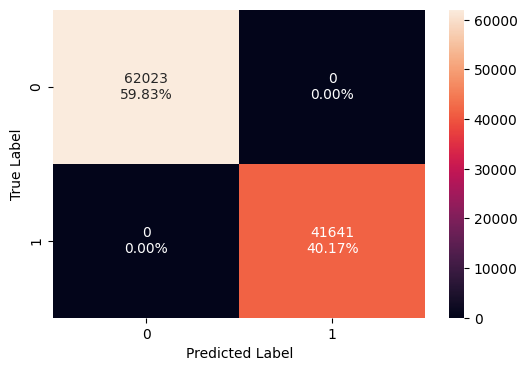

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Training Dataset
#------------------------------------------------------------------------------
X_train_use = X_train
y_train_use = y_train
plot_confusion_matrix(xgb_tuned_RSCV, X_train_use, y_train_use)

In [ ]:
#------------------------------------------------------------------------------
# Performance Check - Training Dataset
#------------------------------------------------------------------------------
xgb_estimator_tuned_RSCV_train_perf = model_performance_classification(xgb_tuned_RSCV, X_train_use, y_train_use)
xgb_estimator_tuned_RSCV_train_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


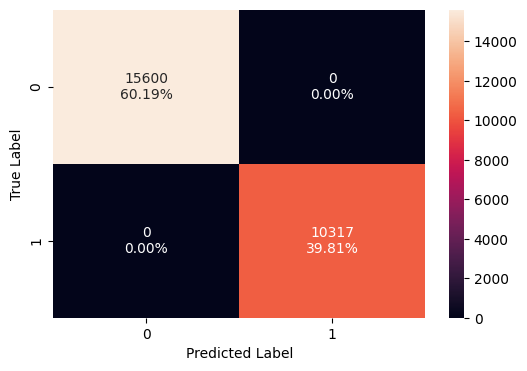

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(xgb_tuned_RSCV, X_val , y_val )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
xgb_estimator_tuned_RSCV_val_perf = model_performance_classification(xgb_tuned_RSCV, X_val , y_val)
xgb_estimator_tuned_RSCV_val_perf

,Accuracy,Recall,Precision,F1 Score
0,1.0,1.0,1.0,1.0


### Observations:
For XGBoost classifier Randomsearch CV is used for training and validation. For this as well Accuracy score, Recall score, Precision score and F1 Score for training and validation data are similar 100%. It exhibit generalized performances.

# 10. Model Performance

## Model with Original Data

### Performance comparison - With Training-Validation Dataset

In [ ]:
#------------------------------------------------------------------------------
# Training-Validation performance comparison
#------------------------------------------------------------------------------

models_comp_df = pd.concat(
    [
        rf_estimator_1_train_perf.T,
        rf_estimator_1_val_perf.T,
        xgb_estimator_1_train_perf.T,
        xgb_estimator_1_val_perf.T,
    ],
    axis=1,
)
models_comp_df.columns = [
    "Random Forest-Training",
    "Random Forest-Val",
    "XGBoost-Training",
    "XGBoost-Val",
]
print("Training-Validation performance comparison:")
models_comp_df

Training-Validation performance comparison:


,Random Forest-Training,Random Forest-Val,XGBoost-Training,XGBoost-Val
Accuracy,1.0,1.0,1.0,1.0
Recall,1.0,1.0,1.0,1.0
Precision,1.0,1.0,1.0,1.0
F1 Score,1.0,1.0,1.0,1.0


### Observations:
For XGBoost and Random forest classifier model- the difference Accuracy score, Recall score, Precision score and F1 Score for training and validation data are same 100%. This is mainly due to the very small target variable size.

## Model with Oversampled and Undersampled Data

### Performance comparison - With Oversampled Data- With Training-Validation Dataset

In [ ]:
#------------------------------------------------------------------------------
# Training-Validation performance comparison
#------------------------------------------------------------------------------

models_comp_df = pd.concat(
    [
        rf_estimator_2_train_perf.T,
        rf_estimator_2_val_perf.T,
        xgb_estimator_2_train_perf.T,
        xgb_estimator_2_val_perf.T,
    ],
    axis=1,
)
models_comp_df.columns = [
    "Random Forest-Training",
    "Random Forest-Val",
    "XGBoost-Training",
    "XGBoost-Val",
]
print("Training-Validation performance comparison:")
models_comp_df

Training-Validation performance comparison:


,Random Forest-Training,Random Forest-Val,XGBoost-Training,XGBoost-Val
Accuracy,1.0,1.0,1.0,1.0
Recall,1.0,1.0,1.0,1.0
Precision,1.0,1.0,1.0,1.0
F1 Score,1.0,1.0,1.0,1.0


### Performance comparison - With Undersampled Data - With Training-Validation Dataset

In [ ]:
#------------------------------------------------------------------------------
# Training-Validation performance comparison
#------------------------------------------------------------------------------

models_comp_df = pd.concat(
    [
        rf_estimator_3_train_perf.T,
        rf_estimator_3_val_perf.T,
        xgb_estimator_3_train_perf.T,
        xgb_estimator_3_val_perf.T,
    ],
    axis=1,
)
models_comp_df.columns = [
    "Random Forest-Training",
    "Random Forest-Val",
    "XGBoost-Training",
    "XGBoost-Val",
]
print("Training-Validation performance comparison:")
models_comp_df

Training-Validation performance comparison:


,Random Forest-Training,Random Forest-Val,XGBoost-Training,XGBoost-Val
Accuracy,1.0,1.0,1.0,1.0
Recall,1.0,1.0,1.0,1.0
Precision,1.0,1.0,1.0,1.0
F1 Score,1.0,1.0,1.0,1.0


### Observations:
With Oversampled and Undersampled Data also, the difference for Accuracy score, Recall score, Precision score and F1 Score for training and validation data are same 100%. This is mainly due to the very small target variable size.

## Model with Hyperparameter tuning

### Performance comparison - With Training-Validation Dataset

In [ ]:
#------------------------------------------------------------------------------
# Training-Validation performance comparison
#------------------------------------------------------------------------------

models_comp_df = pd.concat(
    [
        rf_estimator_tune_GSCV_train_perf.T,
        rf_estimator_tune_GSCV_val_perf.T,
        rf_estimator_tune_RSCV_train_perf.T,
        rf_estimator_tune_RSCV_val_perf.T,
        xgb_estimator_tuned_RSCV_train_perf.T,
        xgb_estimator_tuned_RSCV_val_perf.T,
    ],
    axis=1,
)
models_comp_df.columns = [
    "Random Forest-Training-GSCV",
    "Random Forest-Val-GSCV",
    "Random Forest-Training-RSCV",
    "Random Forest-Val-RSCV",
    "XGBoost-Training-RSCV",
    "XGBoost-Val-RSCV",
]
print("Training-Validation performance comparison for tuned Classification models:")
models_comp_df

Training-Validation performance comparison for tuned Classification models:


,Random Forest-Training-GSCV,Random Forest-Val-GSCV,Random Forest-Training-RSCV,Random Forest-Val-RSCV,XGBoost-Training-RSCV,XGBoost-Val-RSCV
Accuracy,0.998514,0.998688,0.998514,0.998688,1.0,1.0
Recall,0.996302,0.996704,0.996302,0.996704,1.0,1.0
Precision,1.000000,1.000000,1.000000,1.000000,1.0,1.0
F1 Score,0.998147,0.998350,0.998147,0.998350,1.0,1.0


### Observations:

- After hyperparameter tuning, the difference of Accuracy score, Recall score, Precision score and F1 Score for Randomforest classifier for training and validation data are similar for both Grid Search CV and Random Search CV. It exhibit generalized performances.
- To reduce effort and to recommend injury and death cases should be less, it is important to decrease both false postive (FP) and fasle negative cases (FN). So, F1 score need to be high.
- So, **the best model will be that one which has high F1 score and difference between training and validation scores are least**. ( XGBoost is not considered since it is not sure how will it perform with unseens data)
- So **the tuned model "rf_estimator_tuned_RSCV" will be best for test dataset.** "rf_estimator_tuned_RSCV" is a hyperparameter tuned Randomforest classifier model where RandomSearchCV was used (section 9.1).

## Check the performance of the final model on the test data

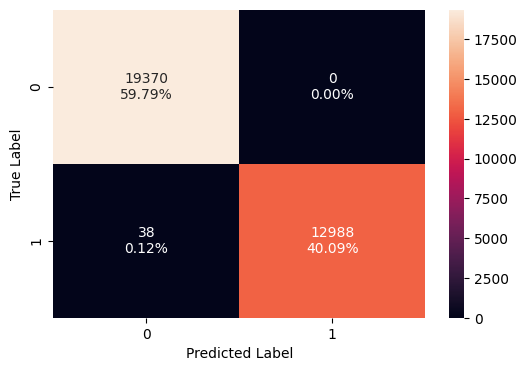

In [ ]:
#------------------------------------------------------------------------------
# Confusion Matrix - Testing Dataset
#------------------------------------------------------------------------------
plot_confusion_matrix(rf_estimator_tuned_RSCV, X_test , y_test )

In [ ]:
#------------------------------------------------------------------------------
# Performance check - Testing Dataset
#------------------------------------------------------------------------------
xgb_estimator_tuned_GSCV_test_perf = model_performance_classification(rf_estimator_tuned_RSCV, X_test , y_test)
xgb_estimator_tuned_GSCV_test_perf

,Accuracy,Recall,Precision,F1 Score
0,0.998827,0.997083,1.0,0.998539


### Observations:
- The Accuracy score, Recall score, Precision score and F1 Score values are very near/similar to the scores of training and validation dataset.
- So, the **model is performing well with unseen data**.

### Feature Importance

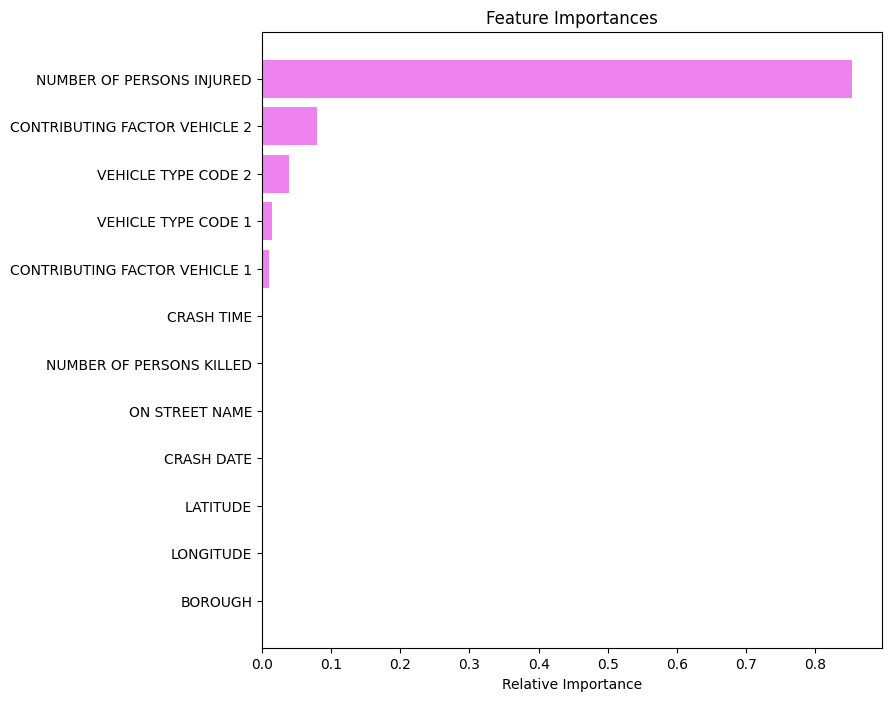

In [ ]:
#------------------------------------------------------------------------------
# Importance of features in the tree building
#------------------------------------------------------------------------------
importances = rf_estimator_tuned_GSCV.feature_importances_
indices = np.argsort(importances)
# list of feature names in X_train
feature_names = list(X_train.columns)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()


### Observations:
- TBD

# 11. Actionable Insights and Recommendations

## Conclusions and Actionable Insights:

- TBD

## Business recommendations:

- TBD

-------------------------------------------